In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations


In [6]:
from pathlib import Path
import pandas as pd

# Define your root directory
ROOT = Path.home() / "Documents" / "SENIOR" / "Extracted_Bacteria (Coli+Aureus)"

files = {
    "A": "DRIAMS_A/DRIAMS_A_SHORT_LIST.xlsx",
    "B": "DRIAMS_B/DRIAMS_B_SHORT_LIST.xlsx",
    "C": "DRIAMS_C/DRIAMS_C_SHORT_LIST.xlsx",
    "D": "DRIAMS_D/DRIAMS_D_SHORT_LIST.xlsx",
}

dfs = []
for hospital, relative_path in files.items():
    file_path = ROOT / relative_path  # Combines ROOT with relative file path
    d = pd.read_excel(file_path)
    d["hospital"] = hospital
    dfs.append(d)

df = pd.concat(dfs, ignore_index=True)
df["Cotrimoxazole"] = df["Cotrimoxazole"].combine_first(df["Cotrimoxazol"])
df = df.drop(columns=["Cotrimoxazol", "Unnamed: 0", "Unnamed: 0.1", "combined_code"], errors="ignore")

print(df.shape)

(21532, 116)


### Data Loading and Integration

The four DRIAMS datasets/hospitals (A, B, C, and D) were combined into a single dataframe. A new `hospital` column was added to preserve the source of each observation.

After combining and cleaning the datasets:

- **Observations:** 21,532
- **Columns:** 116

The columns `Cotrimoxazole` and `Cotrimoxazol` were also merged because they represent the same antibiotic under different spellings.

In [8]:
# STEP 2 — profile ALL antibiotic columns (not just a guessed top-N)
exclude = ["code", "species", "laboratory_species", "genus", "sample_type",
           "year", "hospital", "ESBL", "MRSA", "Quinolones", "Aminoglycosides"] #exculde the non-antibiotic columns
antibiotic_cols = [c for c in df.columns if c not in exclude]

profile = pd.DataFrame({
    "Total_isolates": len(df),
    "R_count": df[antibiotic_cols].apply(lambda c: (c == "R").sum()),
    "S_count": df[antibiotic_cols].apply(lambda c: (c == "S").sum()),
    "I_count": df[antibiotic_cols].apply(lambda c: (c == "I").sum()),
})

profile["Missing_count"] = profile["Total_isolates"] - (profile["R_count"] + profile["S_count"] + profile["I_count"])
profile["Percent_tested"] = ((profile["R_count"] + profile["S_count"] + profile["I_count"]) / profile["Total_isolates"] * 100).round(1)
# I is excluded from the denominator in calculating the R% -> Binary Analysis (R/S)
profile["R_percent"] = (profile["R_count"] / (profile["R_count"] + profile["S_count"]).replace(0, np.nan) * 100).round(1)
profile.sort_values("Percent_tested", ascending=False)

,Total_isolates,R_count,S_count,I_count,Missing_count,Percent_tested,R_percent
Ciprofloxacin,21532,2688,12056,212,6576,69.5,18.2
Amoxicillin-Clavulanic acid,21532,2574,10070,15,8873,58.8,20.4
Ceftriaxone,21532,2188,9532,4,9808,54.4,18.7
Cefepime,21532,1304,9813,590,9825,54.4,11.7
Cotrimoxazole,21532,2704,8704,2,10122,53.0,23.7
...,...,...,...,...,...,...,...
Penicillin_with_pneumonia,21532,0,0,0,21532,0.0,NaN
Meropenem_with_pneumonia,21532,0,0,0,21532,0.0,NaN
Ticarcillin-Clavulan acid,21532,0,1,0,21531,0.0,0.0
Penicillin_without_endokarditis,21532,0,0,0,21532,0.0,NaN


In [9]:
# STEP 3 — Build antibiotic selection table
selection_df = pd.DataFrame({
    "Antibiotic": antibiotic_cols,
    "R": [profile.loc[a, "R_count"] for a in antibiotic_cols],
    "S": [profile.loc[a, "S_count"] for a in antibiotic_cols],
    "I": [profile.loc[a, "I_count"] for a in antibiotic_cols]
})

# Total available AST results: R + S + I
selection_df["Tested"] = (
    selection_df["R"] +
    selection_df["S"] +
    selection_df["I"]
)

selection_df["Coverage"] = (
    selection_df["Tested"] / len(df)
)

# Usable observations for our binary R/S analysis
selection_df["RS_Usable"] = (
    selection_df["R"] +
    selection_df["S"]
)

selection_df["RS_Usable_Coverage"] = (
    selection_df["RS_Usable"] / len(df)
)

selection_df = selection_df.sort_values(
    "RS_Usable_Coverage",
    ascending=False
).reset_index(drop=True)

display(selection_df.head(30))

,Antibiotic,R,S,I,Tested,Coverage,RS_Usable,RS_Usable_Coverage
0,Ciprofloxacin,2688,12056,212,14956,0.694594,14744,0.684748
1,Amoxicillin-Clavulanic acid,2574,10070,15,12659,0.587916,12644,0.587219
2,Ceftriaxone,2188,9532,4,11724,0.544492,11720,0.544306
3,Cotrimoxazole,2704,8704,2,11410,0.529909,11408,0.529816
4,Imipenem,719,10624,0,11343,0.526797,11343,0.526797
5,Piperacillin-Tazobactam,1198,9992,55,11245,0.522246,11190,0.519692
6,Cefepime,1304,9813,590,11707,0.543702,11117,0.516301
7,Gentamicin,429,9565,3,9997,0.464286,9994,0.464146
8,Meropenem,715,8789,0,9504,0.441390,9504,0.441390
9,Ampicillin-Amoxicillin,5527,2895,0,8422,0.391139,8422,0.391139


In [10]:
# STEP 4 — Select antibiotics with sufficient usable R/S data
MIN_COVERAGE = 0.20
MIN_RESISTANT = 30

eligible = selection_df[
    (selection_df["RS_Usable_Coverage"] >= MIN_COVERAGE) &
    (selection_df["R"] >= MIN_RESISTANT)
].copy()

eligible = eligible.sort_values(
    by=["RS_Usable_Coverage", "R"],
    ascending=[False, False]
).reset_index(drop=True)

selected = eligible["Antibiotic"].tolist()

print("Number of eligible antibiotics:", len(selected))
display(eligible)

Number of eligible antibiotics: 25


,Antibiotic,R,S,I,Tested,Coverage,RS_Usable,RS_Usable_Coverage
0,Ciprofloxacin,2688,12056,212,14956,0.694594,14744,0.684748
1,Amoxicillin-Clavulanic acid,2574,10070,15,12659,0.587916,12644,0.587219
2,Ceftriaxone,2188,9532,4,11724,0.544492,11720,0.544306
3,Cotrimoxazole,2704,8704,2,11410,0.529909,11408,0.529816
4,Imipenem,719,10624,0,11343,0.526797,11343,0.526797
5,Piperacillin-Tazobactam,1198,9992,55,11245,0.522246,11190,0.519692
6,Cefepime,1304,9813,590,11707,0.543702,11117,0.516301
7,Gentamicin,429,9565,3,9997,0.464286,9994,0.464146
8,Meropenem,715,8789,0,9504,0.441390,9504,0.441390
9,Ampicillin-Amoxicillin,5527,2895,0,8422,0.391139,8422,0.391139


In [11]:
# STEP 5 — Check pairwise co-testing among selected antibiotics
cotest_results = []

for a, b in combinations(selected, 2):

    valid = df[[a, b]].copy()

    valid[a] = valid[a].astype(str).str.strip().str.upper()
    valid[b] = valid[b].astype(str).str.strip().str.upper()

    valid = valid[
        valid[a].isin(["R", "S"]) &
        valid[b].isin(["R", "S"])
    ]

    n_cotested = len(valid)

    cotest_results.append({
        "Antibiotic_A": a,
        "Antibiotic_B": b,
        "N_Cotested": n_cotested,
        "Pct_of_Dataset": n_cotested / len(df) * 100
    })

cotest_df = pd.DataFrame(cotest_results)

print("Number of selected antibiotics:", len(selected))
print("Number of possible pairs:", len(cotest_df))

display(
    cotest_df.sort_values("N_Cotested").reset_index(drop=True)
)

Number of selected antibiotics: 25
Number of possible pairs: 300


,Antibiotic_A,Antibiotic_B,N_Cotested,Pct_of_Dataset
0,Amikacin,Erythromycin,0,0.000000
1,Amikacin,Daptomycin,0,0.000000
2,Amikacin,Oxacillin,0,0.000000
3,Erythromycin,Tobramycin,0,0.000000
4,Tobramycin,Daptomycin,0,0.000000
...,...,...,...,...
295,Amoxicillin-Clavulanic acid,Imipenem,11149,51.778748
296,Ceftriaxone,Imipenem,11298,52.470741
297,Ciprofloxacin,Ceftriaxone,11333,52.633290
298,Amoxicillin-Clavulanic acid,Ceftriaxone,11529,53.543563


In [12]:
# STEP 6 — Examine pairwise co-testing distribution
print("Summary of N_Cotested:")
display(cotest_df["N_Cotested"].describe())

thresholds = [10, 30, 50, 100, 200, 500, 1000]

print("\nPairs below possible thresholds:")
for threshold in thresholds:
    n_below = (cotest_df["N_Cotested"] < threshold).sum()
    pct_below = n_below / len(cotest_df) * 100

    print(
        f"< {threshold}: {n_below} pairs "
        f"({pct_below:.1f}%)"
    )

Summary of N_Cotested:


count      300.000000
mean      4344.576667
std       2896.695292
min          0.000000
25%       3542.500000
50%       4221.000000
75%       5619.250000
max      12269.000000
Name: N_Cotested, dtype: float64


Pairs below possible thresholds:
< 10: 38 pairs (12.7%)
< 30: 38 pairs (12.7%)
< 50: 38 pairs (12.7%)
< 100: 38 pairs (12.7%)
< 200: 38 pairs (12.7%)
< 500: 51 pairs (17.0%)
< 1000: 55 pairs (18.3%)


In [13]:
# STEP 7 — Calculate pairwise R/S resistance combinations
pair_results = []

for a, b in combinations(selected, 2):

    # Keep only the two antibiotics being compared
    valid = df[[a, b]].copy()

    # Standardize AST labels
    valid[a] = valid[a].astype(str).str.strip().str.upper()
    valid[b] = valid[b].astype(str).str.strip().str.upper()

    # Keep only isolates with definitive R/S results for BOTH antibiotics
    valid = valid[
        valid[a].isin(["R", "S"]) &
        valid[b].isin(["R", "S"])
    ]

    # Number of isolates co-tested for this pair
    n_cotested = len(valid)

    # Four possible R/S combinations
    rr = ((valid[a] == "R") & (valid[b] == "R")).sum()
    rs = ((valid[a] == "R") & (valid[b] == "S")).sum()
    sr = ((valid[a] == "S") & (valid[b] == "R")).sum()
    ss = ((valid[a] == "S") & (valid[b] == "S")).sum()

    pair_results.append({
        "Antibiotic_A": a,
        "Antibiotic_B": b,
        "N_Cotested": n_cotested,
        "RR": rr,
        "RS": rs,
        "SR": sr,
        "SS": ss
    })

pair_results_df = pd.DataFrame(pair_results)

print("Number of calculated pairs:", len(pair_results_df))

display(pair_results_df.head(10))

Number of calculated pairs: 300


,Antibiotic_A,Antibiotic_B,N_Cotested,RR,RS,SR,SS
0,Ciprofloxacin,Amoxicillin-Clavulanic acid,12269,1144,1275,1341,8509
1,Ciprofloxacin,Ceftriaxone,11333,1302,1136,772,8123
2,Ciprofloxacin,Cotrimoxazole,11055,1131,1221,1453,7250
3,Ciprofloxacin,Imipenem,10961,294,2046,412,8209
4,Ciprofloxacin,Piperacillin-Tazobactam,10816,556,1722,601,7937
5,Ciprofloxacin,Cefepime,10785,729,1220,540,8296
6,Ciprofloxacin,Gentamicin,9766,228,1026,170,8342
7,Ciprofloxacin,Meropenem,9172,293,1711,409,6759
8,Ciprofloxacin,Ampicillin-Amoxicillin,8127,1637,158,3636,2696
9,Ciprofloxacin,Ceftazidime,7360,583,1061,240,5476


In [14]:
print(
    "All counts sum correctly:",
    (
        pair_results_df["RR"]
        + pair_results_df["RS"]
        + pair_results_df["SR"]
        + pair_results_df["SS"]
        == pair_results_df["N_Cotested"]
    ).all()
)

All counts sum correctly: True


In [15]:
# STEP 8 — Calculate pairwise resistance-overlap measures

# Number resistant to at least one antibiotic in the pair
pair_results_df["N_Resistant_Union"] = (
    pair_results_df["RR"]
    + pair_results_df["RS"]
    + pair_results_df["SR"]
)

# Proportion of all co-tested isolates resistant to both
pair_results_df["Joint_R_Prevalence"] = np.where(
    pair_results_df["N_Cotested"] > 0,
    pair_results_df["RR"] / pair_results_df["N_Cotested"],
    np.nan
)

# Normalized overlap among isolates resistant to at least one antibiotic
pair_results_df["Normalized_CR"] = np.where(
    pair_results_df["N_Resistant_Union"] > 0,
    pair_results_df["RR"] / pair_results_df["N_Resistant_Union"],
    np.nan
)

display(
    pair_results_df[
        [
            "Antibiotic_A",
            "Antibiotic_B",
            "N_Cotested",
            "RR",
            "RS",
            "SR",
            "SS",
            "N_Resistant_Union",
            "Joint_R_Prevalence",
            "Normalized_CR"
        ]
    ].head(10)
)

,Antibiotic_A,Antibiotic_B,N_Cotested,RR,RS,SR,SS,N_Resistant_Union,Joint_R_Prevalence,Normalized_CR
0,Ciprofloxacin,Amoxicillin-Clavulanic acid,12269,1144,1275,1341,8509,3760,0.093243,0.304255
1,Ciprofloxacin,Ceftriaxone,11333,1302,1136,772,8123,3210,0.114886,0.405607
2,Ciprofloxacin,Cotrimoxazole,11055,1131,1221,1453,7250,3805,0.102307,0.297240
3,Ciprofloxacin,Imipenem,10961,294,2046,412,8209,2752,0.026822,0.106831
4,Ciprofloxacin,Piperacillin-Tazobactam,10816,556,1722,601,7937,2879,0.051405,0.193123
5,Ciprofloxacin,Cefepime,10785,729,1220,540,8296,2489,0.067594,0.292889
6,Ciprofloxacin,Gentamicin,9766,228,1026,170,8342,1424,0.023346,0.160112
7,Ciprofloxacin,Meropenem,9172,293,1711,409,6759,2413,0.031945,0.121426
8,Ciprofloxacin,Ampicillin-Amoxicillin,8127,1637,158,3636,2696,5431,0.201427,0.301418
9,Ciprofloxacin,Ceftazidime,7360,583,1061,240,5476,1884,0.079212,0.309448


In [16]:
# STEP 9 — Examine resistance-positive sample size
MIN_COTESTED = 200

cotested_pairs = pair_results_df[
    pair_results_df["N_Cotested"] >= MIN_COTESTED
].copy()

print("Pairs with N_Cotested >= 200:", len(cotested_pairs))

print("\nSummary of N_Resistant_Union:")
display(cotested_pairs["N_Resistant_Union"].describe())

thresholds = [1, 5, 10, 20, 30, 50, 100, 200]

print("\nPairs below possible resistance-positive thresholds:")
for threshold in thresholds:

    n_below = (
        cotested_pairs["N_Resistant_Union"] < threshold
    ).sum()

    pct_below = (
        n_below / len(cotested_pairs) * 100
    )

    print(
        f"< {threshold}: {n_below} pairs "
        f"({pct_below:.1f}%)"
    )

Pairs with N_Cotested >= 200: 262

Summary of N_Resistant_Union:


count     262.00000
mean     1364.01145
std      1225.42037
min        10.00000
25%       666.75000
50%       960.50000
75%      1879.00000
max      5567.00000
Name: N_Resistant_Union, dtype: float64


Pairs below possible resistance-positive thresholds:
< 1: 0 pairs (0.0%)
< 5: 0 pairs (0.0%)
< 10: 0 pairs (0.0%)
< 20: 5 pairs (1.9%)
< 30: 13 pairs (5.0%)
< 50: 19 pairs (7.3%)
< 100: 25 pairs (9.5%)
< 200: 32 pairs (12.2%)


In [17]:
print("Resistance-positive denominator summary:")

print(
    pair_results_df[
        pair_results_df["N_Cotested"] >= 200
    ]["N_Resistant_Union"].describe()
)

thresholds = [1, 5, 10, 20, 30, 50, 100, 200]

print("\nPairs below each resistant-union threshold:")

eligible_pairs = pair_results_df[
    pair_results_df["N_Cotested"] >= 200
]

for threshold in thresholds:

    n = (
        eligible_pairs["N_Resistant_Union"] < threshold
    ).sum()

    pct = n / len(eligible_pairs) * 100

    print(
        f"< {threshold:3}: "
        f"{n:3} pairs ({pct:.1f}%)"
    )

Resistance-positive denominator summary:
count     262.00000
mean     1364.01145
std      1225.42037
min        10.00000
25%       666.75000
50%       960.50000
75%      1879.00000
max      5567.00000
Name: N_Resistant_Union, dtype: float64

Pairs below each resistant-union threshold:
<   1:   0 pairs (0.0%)
<   5:   0 pairs (0.0%)
<  10:   0 pairs (0.0%)
<  20:   5 pairs (1.9%)
<  30:  13 pairs (5.0%)
<  50:  19 pairs (7.3%)
< 100:  25 pairs (9.5%)
< 200:  32 pairs (12.2%)


In [18]:
# STEP 10 — Apply pair-level reliability criteria

MIN_COTESTED = 200
MIN_RESISTANT_UNION = 30

pair_results_df["Eligible"] = (
    (pair_results_df["N_Cotested"] >= MIN_COTESTED) &
    (pair_results_df["N_Resistant_Union"] >= MIN_RESISTANT_UNION)
)

# Keep the raw Normalized_CR, but create a filtered version
# for the final heatmap and pattern analysis.
pair_results_df["Filtered_CR"] = np.where(
    pair_results_df["Eligible"],
    pair_results_df["Normalized_CR"],
    np.nan
)

print("Total possible pairs:", len(pair_results_df))
print("Eligible pairs:", pair_results_df["Eligible"].sum())
print("Ineligible pairs:", (~pair_results_df["Eligible"]).sum())

display(
    pair_results_df[
        [
            "Antibiotic_A",
            "Antibiotic_B",
            "N_Cotested",
            "N_Resistant_Union",
            "Normalized_CR",
            "Eligible",
            "Filtered_CR"
        ]
    ].head(10)
)

Total possible pairs: 300
Eligible pairs: 249
Ineligible pairs: 51


,Antibiotic_A,Antibiotic_B,N_Cotested,N_Resistant_Union,Normalized_CR,Eligible,Filtered_CR
0,Ciprofloxacin,Amoxicillin-Clavulanic acid,12269,3760,0.304255,True,0.304255
1,Ciprofloxacin,Ceftriaxone,11333,3210,0.405607,True,0.405607
2,Ciprofloxacin,Cotrimoxazole,11055,3805,0.297240,True,0.297240
3,Ciprofloxacin,Imipenem,10961,2752,0.106831,True,0.106831
4,Ciprofloxacin,Piperacillin-Tazobactam,10816,2879,0.193123,True,0.193123
5,Ciprofloxacin,Cefepime,10785,2489,0.292889,True,0.292889
6,Ciprofloxacin,Gentamicin,9766,1424,0.160112,True,0.160112
7,Ciprofloxacin,Meropenem,9172,2413,0.121426,True,0.121426
8,Ciprofloxacin,Ampicillin-Amoxicillin,8127,5431,0.301418,True,0.301418
9,Ciprofloxacin,Ceftazidime,7360,1884,0.309448,True,0.309448


In [19]:
pair_results_df["Filtered_CR"] = np.where(
    pair_results_df["Eligible"],
    pair_results_df["Normalized_CR"],
    np.nan
)

print("\nFiltered CR values available:",
      pair_results_df["Filtered_CR"].notna().sum())


Filtered CR values available: 249


In [20]:
# STEP 11 — Build the normalized resistance-overlap matrix
cr_matrix = pd.DataFrame(
    np.nan,
    index=selected,
    columns=selected,
    dtype=float
)

for _, row in pair_results_df.iterrows():

    a = row["Antibiotic_A"]
    b = row["Antibiotic_B"]

    if row["Eligible"]:
        value = row["Normalized_CR"]

        cr_matrix.loc[a, b] = value
        cr_matrix.loc[b, a] = value

# Leave diagonal blank
np.fill_diagonal(cr_matrix.values, np.nan)

display(cr_matrix)

,Ciprofloxacin,Amoxicillin-Clavulanic acid,Ceftriaxone,Cotrimoxazole,Imipenem,Piperacillin-Tazobactam,Cefepime,Gentamicin,Meropenem,Ampicillin-Amoxicillin,...,Penicillin,Erythromycin,Fosfomycin,Levofloxacin,Oxacillin,Tobramycin,Cefuroxime,Fusidic acid,Clindamycin,Daptomycin
Ciprofloxacin,NaN,0.304255,0.405607,0.297240,0.106831,0.193123,0.292889,0.160112,0.121426,0.301418,...,0.122028,0.175799,0.035620,1.000000,0.304688,0.307692,0.351151,0.078457,0.140831,0.016978
Amoxicillin-Clavulanic acid,0.304255,NaN,0.454374,0.254532,0.292057,0.509418,0.465560,0.143583,0.344247,0.349100,...,0.238367,0.247569,0.032702,0.306573,0.989770,0.294515,0.802026,0.118280,0.202936,0.011936
Ceftriaxone,0.405607,0.454374,NaN,0.247103,0.327665,0.410235,0.812419,0.153188,0.365128,0.326182,...,0.272588,0.252544,0.032020,0.482911,0.988889,0.329830,0.948583,0.120238,0.208540,0.012278
Cotrimoxazole,0.297240,0.254532,0.247103,NaN,0.020231,0.116170,0.132815,0.172819,0.023938,0.277708,...,0.049360,0.048750,0.027714,0.332707,0.078251,0.230857,0.163772,0.064356,0.033708,0.000000
Imipenem,0.106831,0.292057,0.327665,0.020231,NaN,0.603201,0.557467,0.084103,0.997211,0.129985,...,0.272588,0.252544,0.023256,0.002244,0.988889,0.000000,0.759062,0.120238,0.208540,0.012278
Piperacillin-Tazobactam,0.193123,0.509418,0.410235,0.116170,0.603201,NaN,0.582557,0.111511,0.651184,0.189385,...,0.272379,0.252544,0.035176,0.118962,0.988889,0.149394,0.835979,0.120238,0.208540,0.012278
Cefepime,0.292889,0.465560,0.812419,0.132815,0.557467,0.582557,NaN,0.149333,0.622378,0.212170,...,0.272588,0.247569,0.048387,0.263056,0.989204,0.285217,0.932973,0.122286,0.207780,0.011936
Gentamicin,0.160112,0.143583,0.153188,0.172819,0.084103,0.111511,0.149333,NaN,0.098660,0.036273,...,0.028616,0.052968,0.039216,NaN,0.111247,NaN,0.141885,0.074380,0.070365,0.012121
Meropenem,0.121426,0.344247,0.365128,0.023938,0.997211,0.651184,0.622378,0.098660,NaN,0.129529,...,0.272588,0.252544,NaN,0.002235,0.988889,0.000000,0.928292,0.120238,0.208540,0.012278
Ampicillin-Amoxicillin,0.301418,0.349100,0.326182,0.277708,0.129985,0.189385,0.212170,0.036273,0.129529,NaN,...,0.999617,0.191811,NaN,0.428870,0.275440,0.209270,0.272379,0.071915,0.150038,0.011098


In [21]:
print("Matrix shape:", cr_matrix.shape)

print("Matrix symmetric:", cr_matrix.equals(cr_matrix.T))

print(
    "Non-missing unique pairs:",
    cr_matrix.notna().sum().sum() // 2
)

Matrix shape: (25, 25)
Matrix symmetric: True
Non-missing unique pairs: 249


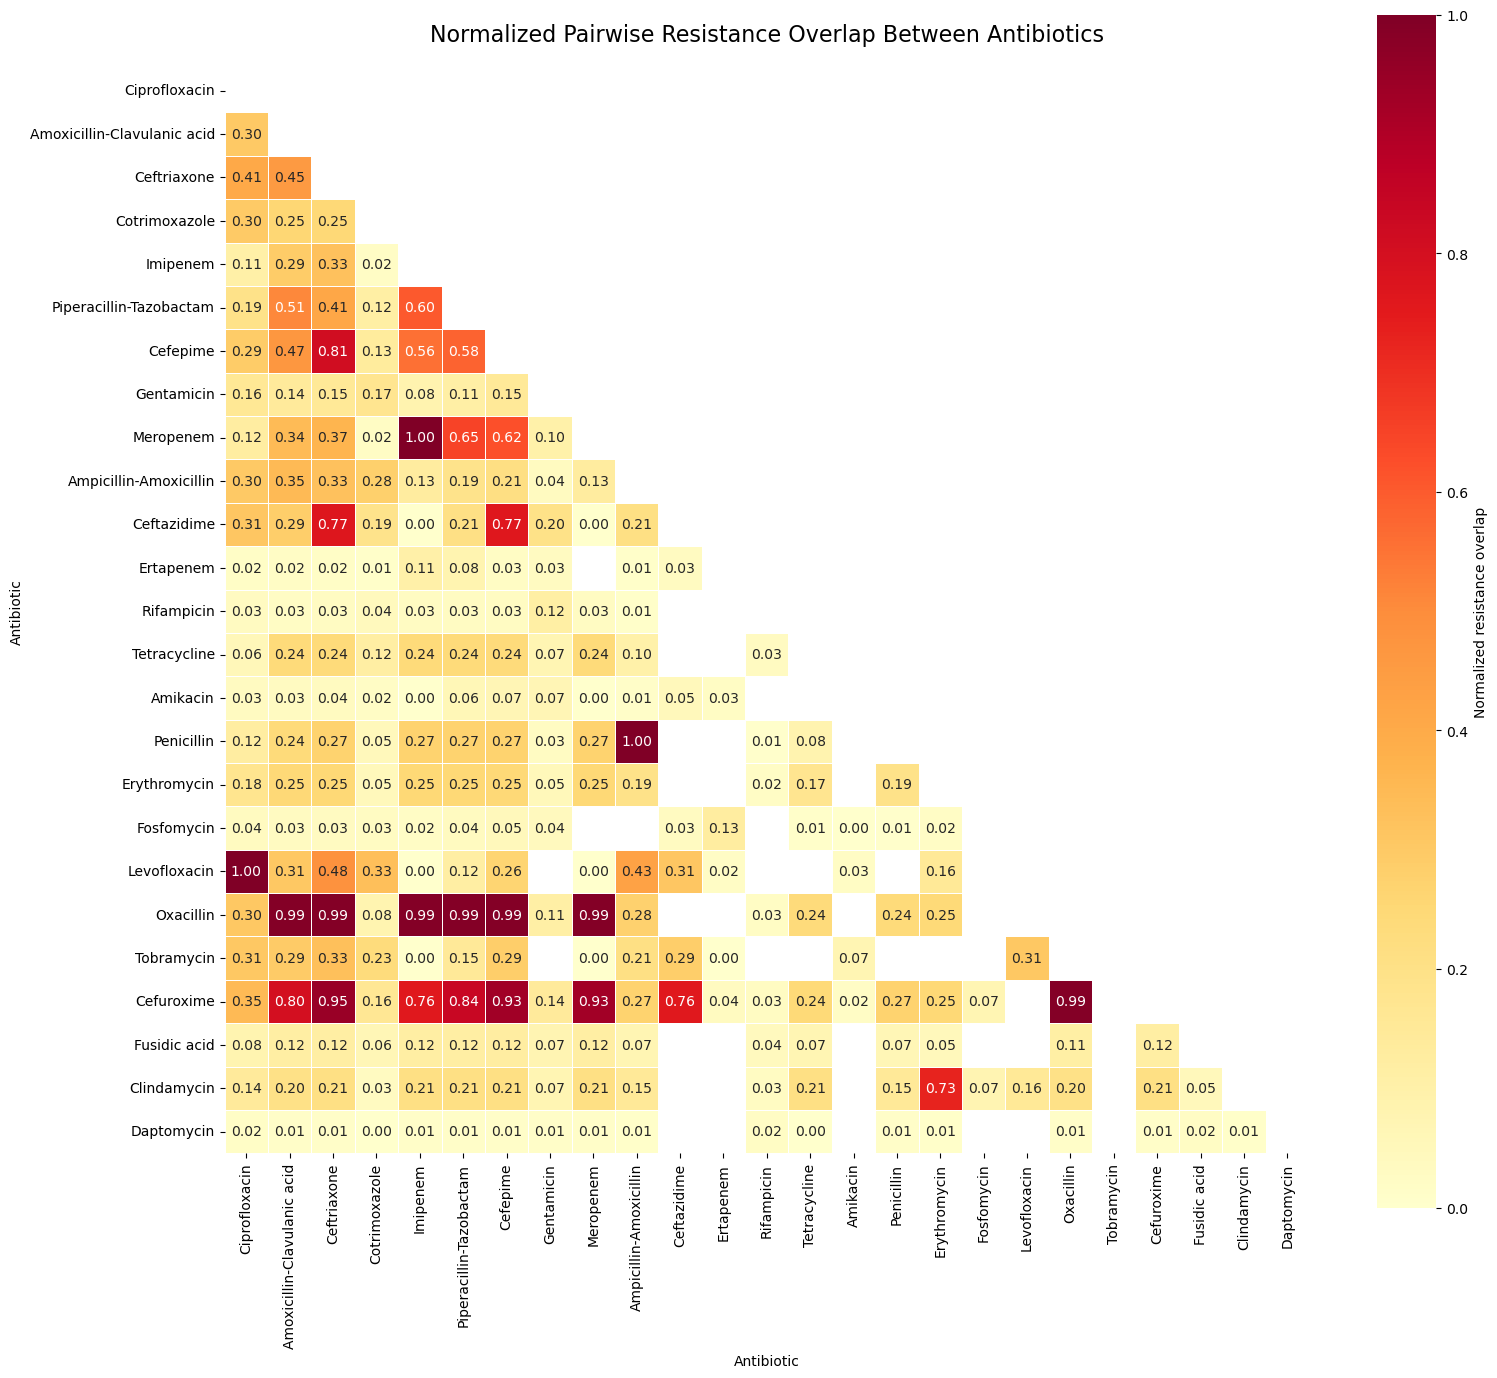

In [22]:
# STEP 12 — Plot triangular normalized resistance-overlap heatmap

# Mask the upper triangle, including the diagonal
triangle_mask = np.triu(
    np.ones(cr_matrix.shape, dtype=bool),
    k=0
)

# Also mask unavailable/ineligible comparisons
final_mask = triangle_mask | cr_matrix.isna().values

plt.figure(figsize=(16, 14))

sns.heatmap(
    cr_matrix,
    mask=final_mask,
    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={
        "label": "Normalized resistance overlap"
    }
)

plt.title(
    "Normalized Pairwise Resistance Overlap Between Antibiotics",
    fontsize=16,
    pad=20
)

plt.xlabel("Antibiotic")
plt.ylabel("Antibiotic")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [23]:
# STEP 13 — Rank eligible antibiotic pairs by normalized resistance overlap
ranked_pairs = (
    pair_results_df[
        pair_results_df["Eligible"]
    ]
    .sort_values(
        "Normalized_CR",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    ranked_pairs[
        [
            "Antibiotic_A",
            "Antibiotic_B",
            "N_Cotested",
            "RR",
            "RS",
            "SR",
            "N_Resistant_Union",
            "Normalized_CR"
        ]
    ].head(25)
)

,Antibiotic_A,Antibiotic_B,N_Cotested,RR,RS,SR,N_Resistant_Union,Normalized_CR
0,Ciprofloxacin,Levofloxacin,5098,1360,0,0,1360,1.000000
1,Ampicillin-Amoxicillin,Penicillin,3554,2611,0,1,2612,0.999617
2,Imipenem,Meropenem,9479,715,2,0,717,0.997211
3,Amoxicillin-Clavulanic acid,Oxacillin,4723,774,0,8,782,0.989770
4,Cefepime,Oxacillin,3985,733,0,8,741,0.989204
5,Meropenem,Oxacillin,3642,712,0,8,720,0.988889
6,Ceftriaxone,Oxacillin,3639,712,0,8,720,0.988889
7,Piperacillin-Tazobactam,Oxacillin,3641,712,0,8,720,0.988889
8,Oxacillin,Cefuroxime,3639,712,8,0,720,0.988889
9,Imipenem,Oxacillin,3640,712,0,8,720,0.988889


In [24]:
from pathlib import Path

# Core metadata columns to retain
metadata_cols = ["code", "species", "laboratory_species", "year", "hospital", "sample_type", "genus"]

# Combine metadata columns with your 25 selected antibiotics
cols_to_keep = [col for col in metadata_cols if col in df.columns] + [abx for abx in selected if abx in df.columns]

# Slice dataframe to keep only chosen columns
df_25_abx = df[cols_to_keep].copy()

Export Cleaned Trimmed Dataset

Save the extracted 25-antibiotic subset to an Excel file in the local directory.

In [25]:
# Define output path in folder
output_cleaned_path = Path.home() / "Downloads" / "DRIAMS_Cleaned_25_Antibiotics_Dataset.xlsx"

# Export trimmed dataframe to Excel
df_25_abx.to_excel(output_cleaned_path, index=False)

print(f"Successfully saved dataset with {df_25_abx.shape[1]} columns (Metadata + 25 Antibiotics) to: {output_cleaned_path}")

Successfully saved dataset with 32 columns (Metadata + 25 Antibiotics) to: /Users/joud/Downloads/DRIAMS_Cleaned_25_Antibiotics_Dataset.xlsx


Filter E. coli Isolates for Hospital A

Extract subset of isolates corresponding strictly to Escherichia coli collected at Hospital A

In [26]:
from pathlib import Path
import pandas as pd
import numpy as np

# 1. Extract E. coli from DRIAMS dataset A strictly from df_25_abx
# Fall back to 'laboratory_species' if primary 'species' column is absent
species_col = "species" if "species" in df_25_abx.columns else "laboratory_species"

# Filter for Hospital A isolates containing 'coli' in species designation
df_ecoli_a = df_25_abx[
    (df_25_abx["hospital"] == "A") & 
    (df_25_abx[species_col].astype(str).str.contains("coli", case=False, na=False))
].copy()

Class Imbalance Evaluation Metric

Defines a mathematical threshold function to quantify class imbalance using Imbalance Ratio ($\text{IR} = \frac{\text{Majority}}{\text{Minority}}$) and minority class prevalence percentage

In [27]:
# 2. Function to categorize balance based on mathematical metric (IR & Minority %)
def evaluate_balance(r_count, s_count):
    total_rs = r_count + s_count
    if total_rs == 0:
        return np.nan, np.nan, "No Data"
    
    maj_count = max(r_count, s_count)
    min_count = min(r_count, s_count)
    
    # Calculate Minority Percentage
    p_min = (min_count / total_rs) * 100
    
    # Calculate Imbalance Ratio (IR)
    if min_count == 0:
        ir = np.inf
        category = "Extremely Imbalanced"
    else:
        ir = maj_count / min_count
        if ir < 1.5:
            category = "Balanced"
        elif ir <= 4.0:
            category = "Imbalanced"
        else:
            category = "Extremely Imbalanced"
            
    return round(ir, 2) if ir != np.inf else "Inf", round(p_min, 2), category

Compute Antibiotic Resistance Profiles & Imbalance Statistics

Iterate through the selected antibiotics to compute testing frequencies ($R$, $S$, $I$), resistance/susceptibility percentages, and classify dataset balance.

In [28]:
# 3. Analyze each antibiotic
ecoli_analysis = []

for abx in selected:
    if abx not in df_ecoli_a.columns:
        continue
        
    # Standardize AST strings (strip spaces & convert to uppercase)
    abx_series = df_ecoli_a[abx].astype(str).str.strip().str.upper()
    
    r_count = (abx_series == "R").sum()
    s_count = (abx_series == "S").sum()
    i_count = (abx_series == "I").sum()
    
    rs_total = r_count + s_count
    total_tested = rs_total + i_count
    
    # R/S proportions calculated relative to valid binary outcomes (excluding 'I')
    r_pct = (r_count / rs_total * 100) if rs_total > 0 else np.nan
    s_pct = (s_count / rs_total * 100) if rs_total > 0 else np.nan
    
    ir_val, p_min_val, balance_cat = evaluate_balance(r_count, s_count)
    
    ecoli_analysis.append({
        "Antibiotic": abx,
        "R_count": r_count,
        "S_count": s_count,
        "I_count": i_count,
        "Total_RS": rs_total,
        "Total_Tested": total_tested,
        "R_Ratio_%": round(r_pct, 2) if pd.notna(r_pct) else np.nan,
        "S_Ratio_%": round(s_pct, 2) if pd.notna(s_pct) else np.nan,
        "Imbalance_Ratio": ir_val,
        "Minority_%": p_min_val,
        "Balance_Category": balance_cat
    })

Display Summary Table & Export Results

In [29]:
# Convert to DataFrame & display
ecoli_summary_df = pd.DataFrame(ecoli_analysis)
display(ecoli_summary_df)

# Save to Excel
output_ecoli_path = Path.home() / "Downloads" / "DRIAMS_A_Ecoli_Antibiotic_Ratios.xlsx"
ecoli_summary_df.to_excel(output_ecoli_path, index=False)

print(f"E. coli balance analysis exported to: {output_ecoli_path}")

,Antibiotic,R_count,S_count,I_count,Total_RS,Total_Tested,R_Ratio_%,S_Ratio_%,Imbalance_Ratio,Minority_%,Balance_Category
0,Ciprofloxacin,1371,3445,95,4816,4911,28.47,71.53,2.51,28.47,Imbalanced
1,Amoxicillin-Clavulanic acid,1177,3649,0,4826,4826,24.39,75.61,3.1,24.39,Imbalanced
2,Ceftriaxone,1085,3875,1,4960,4961,21.88,78.12,3.57,21.88,Imbalanced
3,Cotrimoxazole,1595,3293,0,4888,4888,32.63,67.37,2.06,32.63,Imbalanced
4,Imipenem,5,4918,0,4923,4923,0.10,99.90,983.6,0.10,Extremely Imbalanced
5,Piperacillin-Tazobactam,306,4449,44,4755,4799,6.44,93.56,14.54,6.44,Extremely Imbalanced
6,Cefepime,335,4051,504,4386,4890,7.64,92.36,12.09,7.64,Extremely Imbalanced
7,Gentamicin,0,0,0,0,0,NaN,NaN,NaN,NaN,No Data
8,Meropenem,3,4925,0,4928,4928,0.06,99.94,1641.67,0.06,Extremely Imbalanced
9,Ampicillin-Amoxicillin,2913,1953,0,4866,4866,59.86,40.14,1.49,40.14,Balanced


E. coli balance analysis exported to: /Users/joud/Downloads/DRIAMS_A_Ecoli_Antibiotic_Ratios.xlsx


In [31]:
# E. coli from Hospital A only, ALL antibiotic columns
ecoli_a = df[
    (df["hospital"] == "A")
    & df["species"].astype(str).str.contains("coli", case=False, na=False)
]

rows = []
for abx in antibiotic_cols:
    s = ecoli_a[abx].astype(str).str.strip().str.upper()
    rows.append({"Antibiotic": abx, "R": (s == "R").sum(), "S": (s == "S").sum()})

ecoli_a_counts = pd.DataFrame(rows).sort_values("R", ascending=False)

# How many antibiotics pass each minimum (R and S)
for t in [30, 100, 300]:
    n = ((ecoli_a_counts["R"] >= t) & (ecoli_a_counts["S"] >= t)).sum()
    print(f"At least {t} R and {t} S: {n} antibiotics")

display(ecoli_a_counts.head(30))

At least 30 R and 30 S: 15 antibiotics
At least 100 R and 100 S: 12 antibiotics
At least 300 R and 300 S: 12 antibiotics


,Antibiotic,R,S
29,Ampicillin-Amoxicillin,2913,1953
4,Cotrimoxazole,1595,3293
2,Ciprofloxacin,1371,3445
7,Levofloxacin,1346,3415
13,Amoxicillin-Clavulanic acid,1177,3649
10,Ceftriaxone,1085,3875
31,Cefpodoxime,874,1201
9,Tobramycin,604,4240
5,Ceftazidime,506,3951
32,Norfloxacin,372,1098


In [32]:
# New antibiotic list, chosen from Hospital A E. coli only
MIN_R, MIN_S = 30, 30

selected_a = ecoli_a_counts[
    (ecoli_a_counts["R"] >= MIN_R) & (ecoli_a_counts["S"] >= MIN_S)
]["Antibiotic"].tolist()

print(len(selected_a), "antibiotics:")
print(selected_a)

15 antibiotics:
['Ampicillin-Amoxicillin', 'Cotrimoxazole', 'Ciprofloxacin', 'Levofloxacin', 'Amoxicillin-Clavulanic acid', 'Ceftriaxone', 'Cefpodoxime', 'Tobramycin', 'Ceftazidime', 'Norfloxacin', 'Cefepime', 'Piperacillin-Tazobactam', 'Amikacin', 'Fosfomycin-Trometamol', 'Ertapenem']


In [33]:
rows = []
for abx in selected_a:
    s = ecoli_a[abx].astype(str).str.strip().str.upper()
    r, sus, i = (s == "R").sum(), (s == "S").sum(), (s == "I").sum()
    ir, p_min, cat = evaluate_balance(r, sus)
    rows.append({
        "Antibiotic": abx, "R": r, "S": sus, "I": i,
        "R_%": round(r / (r + sus) * 100, 1),
        "Imbalance_Ratio": ir, "Minority_%": p_min, "Balance_Category": cat,
    })

balance_a = pd.DataFrame(rows).sort_values("R", ascending=False)
display(balance_a)

,Antibiotic,R,S,I,R_%,Imbalance_Ratio,Minority_%,Balance_Category
0,Ampicillin-Amoxicillin,2913,1953,0,59.9,1.49,40.14,Balanced
1,Cotrimoxazole,1595,3293,0,32.6,2.06,32.63,Imbalanced
2,Ciprofloxacin,1371,3445,95,28.5,2.51,28.47,Imbalanced
3,Levofloxacin,1346,3415,97,28.3,2.54,28.27,Imbalanced
4,Amoxicillin-Clavulanic acid,1177,3649,0,24.4,3.10,24.39,Imbalanced
5,Ceftriaxone,1085,3875,1,21.9,3.57,21.88,Imbalanced
6,Cefpodoxime,874,1201,0,42.1,1.37,42.12,Balanced
7,Tobramycin,604,4240,32,12.5,7.02,12.47,Extremely Imbalanced
8,Ceftazidime,506,3951,365,11.4,7.81,11.35,Extremely Imbalanced
9,Norfloxacin,372,1098,18,25.3,2.95,25.31,Imbalanced


In [34]:
print("Total antibiotic columns:", len(antibiotic_cols))
print("Tested at all (R or S) for E. coli, Hospital A:",
      ((ecoli_a_counts["R"] + ecoli_a_counts["S"]) > 0).sum())

Total antibiotic columns: 105
Tested at all (R or S) for E. coli, Hospital A: 32


In [35]:
from itertools import combinations

# E. coli, all hospitals
ecoli_all = df[df["species"].astype(str).str.contains("coli", case=False, na=False)]

def count_usable(hospitals, min_r=30, min_s=30, strong_r=300):
    sub = ecoli_all[ecoli_all["hospital"].isin(hospitals)]
    ok, strong = 0, 0
    for abx in antibiotic_cols:
        s = sub[abx].astype(str).str.strip().str.upper()
        r, sus = (s == "R").sum(), (s == "S").sum()
        if r >= min_r and sus >= min_s:
            ok += 1
            if r >= strong_r:
                strong += 1
    return ok, strong

print("E. coli isolates per hospital:")
print(ecoli_all["hospital"].value_counts().sort_index(), "\n")

results = []
for k in range(1, 5):
    for combo in combinations(["A", "B", "C", "D"], k):
        ok, strong = count_usable(list(combo))
        results.append({"Hospitals": "+".join(combo),
                        "Antibiotics (30 R and 30 S)": ok,
                        "Reliable (300 R or more)": strong})

display(pd.DataFrame(results))

E. coli isolates per hospital:
hospital
A    7320
B     838
C     927
D    2013
Name: count, dtype: int64 



,Hospitals,Antibiotics (30 R and 30 S),Reliable (300 R or more)
0,A,15,12
1,B,10,0
2,C,12,2
3,D,9,3
4,A+B,17,12
5,A+C,19,13
6,A+D,18,13
7,B+C,12,2
8,B+D,12,4
9,C+D,12,6


# The new task

In [42]:
# Folder where all the DRIAMS data is stored on my laptop
ROOT = Path.home() / "Documents" / "SENIOR" / "Extracted_Bacteria (Coli+Aureus)"

In [45]:
# Folder with the 4 year folders (2015-2018) of Hospital A spectra
# (keep the path you used before)
folder = ROOT / "DRIAMS_A" / "selected_Binned"

# For each year, collect every spectrum file (.txt) and show how many there are
year_files = {}
for y in ["2015", "2016", "2017", "2018"]:
    year_files[y] = [f for f in (folder / y).iterdir() if f.suffix == ".txt"]
    print(y, "->", len(year_files[y]), "spectra files")   # files per year

# One dictionary for all years: file name (= isolate code) -> file path
all_codes = {f.stem: f for files in year_files.values() for f in files}
print("Total spectra files (all years):", len(all_codes))

# Codes of the E. coli isolates from Hospital A (from the Excel table)
ecoli_codes = set(ecoli_a["code"].astype(str).str.strip())
print("E. coli isolates in the table:", len(ecoli_codes))

# Keep only the spectra whose code is an E. coli isolate
match_codes = [c for c in all_codes if c in ecoli_codes]
print("E. coli spectra matched:", len(match_codes))

# How many E. coli rows in the table have NO spectrum file (should be 0 or small)
print("E. coli without a spectrum:", len(ecoli_codes - set(all_codes)))

2015 -> 272 spectra files
2016 -> 4031 spectra files
2017 -> 5850 spectra files
2018 -> 4161 spectra files
Total spectra files (all years): 14314
E. coli isolates in the table: 7320
E. coli spectra matched: 7320
E. coli without a spectrum: 0


In [47]:
# Load the 7,320 E. coli spectra into one matrix 
# it reads each E. coli spectrum file and stacks them into one table, X_spec, 
# where each row is an isolate and each column is one of the 6,000 bins.

import numpy as np

rows, kept_codes = [], []   # rows = one spectrum each, kept_codes = their codes

for i, c in enumerate(match_codes):
    # Read one spectrum file: 2 columns (bin_index, binned_intensity)
    d = pd.read_csv(all_codes[c], sep=r"\s+")

    # Take only the intensity column (6,000 numbers), as float32 to save memory
    v = d["binned_intensity"].to_numpy(dtype="float32")

    # Safety check: keep the spectrum only if it has exactly 6,000 bins
    if len(v) == 6000:
        rows.append(v)          # save the 6,000 intensities
        kept_codes.append(c)    # save the code, so we know which row is which isolate

    # Progress message every 1,000 files (loading takes a while)
    if (i + 1) % 1000 == 0: print(i + 1, "files read")

# Stack all spectra into one table: rows = isolates, columns = 6,000 bins
X_spec = np.vstack(rows)
print("Spectra matrix:", X_spec.shape)                  # expected (7320, 6000)
print("Any missing values:", np.isnan(X_spec).any())    # expected False

1000 files read
2000 files read
3000 files read
4000 files read
5000 files read
6000 files read
7000 files read
Spectra matrix: (7320, 6000)
Any missing values: False


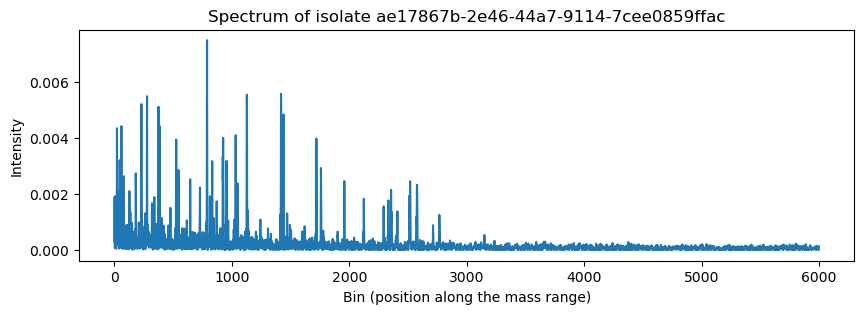

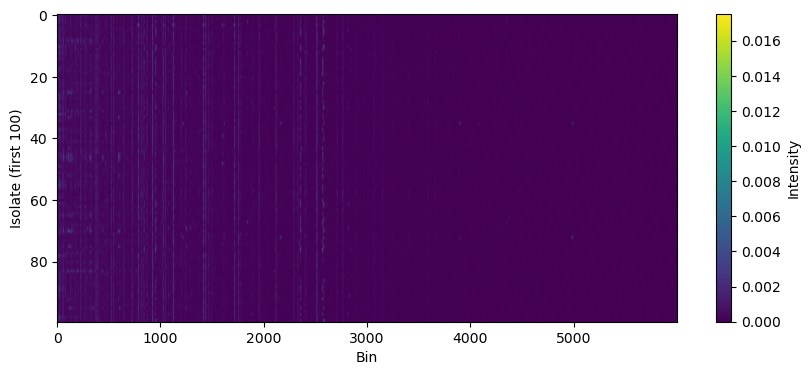

In [49]:
# for visualization of the previous cell

import matplotlib.pyplot as plt

# 1) One spectrum as a line: x = bin, y = intensity (peaks = proteins)
plt.figure(figsize=(10, 3))
plt.plot(X_spec[0])
plt.xlabel("Bin (position along the mass range)")
plt.ylabel("Intensity")
plt.title(f"Spectrum of isolate {kept_codes[0]}")
plt.show()

# 2) First 100 spectra as a heatmap: each row = one isolate, bright = strong signal
plt.figure(figsize=(10, 4))
plt.imshow(X_spec[:100], aspect="auto", cmap="viridis")
plt.xlabel("Bin")
plt.ylabel("Isolate (first 100)")
plt.colorbar(label="Intensity")
plt.show()

the follwowing cell gives every spectrum an R/S label for each antibiotic and a fold number (0 to 4), then saves everything so all three members use the same data and the same splits.

Why the folds are made now: if everyone made their own random split, the results couldn’t be compared. With fixed folds, all methods are tested on exactly the same isolates.

Why -1 and NaN: not every isolate was tested against every antibiotic. Those rows have no label, so they get NaN and fold -1, and the models skip them.


In [50]:
from sklearn.model_selection import StratifiedKFold

# Table with one row per E. coli isolate (code as the index), to look up the R/S results
src = ecoli_a.drop_duplicates("code").set_index("code")

# Start the labels table with the codes, in the SAME order as the rows of X_spec
labels = pd.DataFrame({"code": kept_codes})
labels["year"] = src.loc[kept_codes, "year"].values   # year the sample was taken

# For each of the 15 antibiotics: turn the result into numbers
for abx in selected_a:
    s = src.loc[kept_codes, abx].astype(str).str.strip().str.upper().values
    labels[abx] = pd.Series(s).map({"R": 1, "S": 0})   # R=1, S=0, anything else (I, not tested) = empty (NaN)

# Fold splitter: 5 parts, keeps the R/S ratio in each part, fixed seed so everyone gets the same split
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for abx in selected_a:
    labels[f"fold_{abx}"] = -1                         # -1 = no label for this antibiotic
    idx = np.where(labels[abx].notna().to_numpy())[0]  # rows that HAVE an R or S result
    # Give each labelled row a fold number from 0 to 4
    for k, (_, test_idx) in enumerate(skf.split(idx, labels.loc[idx, abx])):
        labels.loc[idx[test_idx], f"fold_{abx}"] = k

# Save the two shared files for Members 1 and 2
out = Path("shared_data"); out.mkdir(exist_ok=True)
np.save(out / "spectra_ecoli_A.npy", X_spec)           # spectra matrix (7320 x 6000)
labels.to_csv(out / "labels_ecoli_A.csv", index=False) # labels + folds

print("Spectra:", X_spec.shape, "| Labels:", labels.shape)
print(labels[selected_a].notna().sum())   # labelled isolates per antibiotic

Spectra: (7320, 6000) | Labels: (7320, 32)
Ampicillin-Amoxicillin         4866
Cotrimoxazole                  4888
Ciprofloxacin                  4816
Levofloxacin                   4761
Amoxicillin-Clavulanic acid    4826
Ceftriaxone                    4960
Cefpodoxime                    2075
Tobramycin                     4844
Ceftazidime                    4457
Norfloxacin                    1470
Cefepime                       4386
Piperacillin-Tazobactam        4755
Amikacin                       4562
Fosfomycin-Trometamol          1499
Ertapenem                      4978
dtype: int64


## Step 2: Evaluation function `run_cv` and baseline

**Goal:** one common way to test any method, so all members' results are comparable.

**How `run_cv` works:**
1. For one antibiotic, take only the isolates that have an R/S result.
2. Use the saved folds (0 to 4): train on 4 folds, test on the remaining 1, repeated 5 times.
3. Inside each round, the reducer (PCA, Kernel PCA, PSO, ...) is fitted on the **training part only**, to avoid data leakage.
4. A Logistic Regression classifier is trained on the reduced features.
5. We report AUC (Area Under the ROC Curve), PR-AUC (Precision-Recall AUC) and the number of features used.

**Baseline:** no reduction, all 6,000 bins. Every other method must be compared against these numbers.

**Data stays unbalanced.** That is why we use AUC and PR-AUC instead of accuracy.

In [51]:
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

# Reload the shared files (so this cell works for any member)
X = np.load("shared_data/spectra_ecoli_A.npy")
lab = pd.read_csv("shared_data/labels_ecoli_A.csv")

# The 12 antibiotics we model (the other 3 have too few R or S)
MODEL_ABX = ["Ampicillin-Amoxicillin", "Cotrimoxazole", "Ciprofloxacin", "Levofloxacin",
             "Amoxicillin-Clavulanic acid", "Ceftriaxone", "Cefpodoxime", "Tobramycin",
             "Ceftazidime", "Norfloxacin", "Cefepime", "Piperacillin-Tazobactam"]

def run_cv(reducer, antibiotic):
    """reducer = object with fit/transform (PCA, ...) or None for no reduction."""
    has_label = (lab[antibiotic].notna()) & (lab[f"fold_{antibiotic}"] >= 0)
    Xa = X[has_label.values]                      # spectra with an R/S result
    ya = lab.loc[has_label, antibiotic].astype(int).values   # R=1, S=0
    fa = lab.loc[has_label, f"fold_{antibiotic}"].values     # fold number 0-4

    aucs, praucs, n_feats = [], [], []
    for k in range(5):
        tr, te = fa != k, fa == k                 # train = other 4 folds, test = fold k
        steps = [StandardScaler()]                # put all bins on the same scale
        if reducer is not None:
            steps.append(clone(reducer))          # fresh copy, fitted on train only
        steps.append(LogisticRegression(max_iter=1000))   # simple classifier
        model = make_pipeline(*steps).fit(Xa[tr], ya[tr])

        p = model.predict_proba(Xa[te])[:, 1]     # probability of resistant
        aucs.append(roc_auc_score(ya[te], p))
        praucs.append(average_precision_score(ya[te], p))
        # number of features the classifier saw
        n_feats.append(model[:-1].transform(Xa[te][:5]).shape[1])

    return {"antibiotic": antibiotic, "auc": np.mean(aucs), "auc_std": np.std(aucs),
            "prauc": np.mean(praucs), "n_features": int(np.mean(n_feats))}

# Baseline: no reduction, all 6,000 bins, all 12 antibiotics
base = []
for abx in MODEL_ABX:
    r = run_cv(None, abx)
    r["method"] = "baseline_all_bins"
    base.append(r)
    print(abx, "AUC =", round(r["auc"], 3), "| PR-AUC =", round(r["prauc"], 3))

# Save in the shared results format
res = pd.DataFrame(base)[["antibiotic", "method", "auc", "auc_std", "prauc", "n_features"]]
res.to_csv("results_baseline.csv", index=False)
display(res)

Ampicillin-Amoxicillin AUC = 0.648 | PR-AUC = 0.725
Cotrimoxazole AUC = 0.641 | PR-AUC = 0.453
Ciprofloxacin AUC = 0.786 | PR-AUC = 0.631
Levofloxacin AUC = 0.783 | PR-AUC = 0.627
Amoxicillin-Clavulanic acid AUC = 0.616 | PR-AUC = 0.338
Ceftriaxone AUC = 0.843 | PR-AUC = 0.676
Cefpodoxime AUC = 0.835 | PR-AUC = 0.827
Tobramycin AUC = 0.698 | PR-AUC = 0.249
Ceftazidime AUC = 0.796 | PR-AUC = 0.425
Norfloxacin AUC = 0.76 | PR-AUC = 0.583
Cefepime AUC = 0.84 | PR-AUC = 0.403
Piperacillin-Tazobactam AUC = 0.687 | PR-AUC = 0.181


,antibiotic,method,auc,auc_std,prauc,n_features
0,Ampicillin-Amoxicillin,baseline_all_bins,0.647656,0.017540,0.724921,6000
1,Cotrimoxazole,baseline_all_bins,0.641187,0.029877,0.453091,6000
2,Ciprofloxacin,baseline_all_bins,0.785778,0.005049,0.631217,6000
3,Levofloxacin,baseline_all_bins,0.782730,0.024696,0.627203,6000
4,Amoxicillin-Clavulanic acid,baseline_all_bins,0.615787,0.028712,0.338273,6000
5,Ceftriaxone,baseline_all_bins,0.842515,0.010783,0.675867,6000
6,Cefpodoxime,baseline_all_bins,0.835476,0.011734,0.827184,6000
7,Tobramycin,baseline_all_bins,0.697781,0.021814,0.248846,6000
8,Ceftazidime,baseline_all_bins,0.796400,0.022002,0.425361,6000
9,Norfloxacin,baseline_all_bins,0.759515,0.038467,0.583291,6000


## Reduction methods used for the ML phase

Baseline (all 6,000 bins) is above. Three reductions are carried into ML. All are fitted on the **training folds only** (no leakage) and tested with the same `run_cv`, so the only thing that changes is the reduction.

| Method | Type | Features kept | Keeps real bins? |
|---|---|---|---|
| Kernel PCA RBF-200 | Projection | 200 components | No (mixtures of bins) |
| LASSO auto C | Embedded selection | about 224 bins | Yes |
| Grouped ANOVA 300 | Filter | 300 bins (30 windows) | Yes |

In [79]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import KernelPCA
from sklearn.feature_selection import f_classif
from sklearn.model_selection import cross_val_score

def run_all(METHOD_NAME, my_reducer):
    """Run one reduction on the 12 antibiotics with run_cv and save results_<METHOD_NAME>.csv."""
    rows = []
    for abx in MODEL_ABX:
        r = run_cv(my_reducer, abx)
        r["method"] = METHOD_NAME
        rows.append(r)
        print(METHOD_NAME, abx, "AUC =", round(r["auc"], 3),
              "| PR-AUC =", round(r["prauc"], 3), "| features =", r["n_features"])
    res = pd.DataFrame(rows)[["antibiotic", "method", "auc", "auc_std", "prauc", "n_features"]]
    res.to_csv(f"results_{METHOD_NAME}.csv", index=False)
    print(METHOD_NAME, "mean AUC =", round(res.auc.mean(), 3),
          "| mean PR-AUC =", round(res.prauc.mean(), 3), "\n")
    return res

## Kernel PCA (RBF)

**What it does:** builds an N x N similarity table between the training spectra and runs PCA on it. We keep 200 components. The RBF kernel, K(a,b) = exp(-gamma * distance²), can capture non-linear similarity. gamma is the scikit-learn default, 1/6000 (not tuned).
**Why re-scale:** the components have very small values, which the penalty of Logistic Regression would suppress, so a `StandardScaler` is applied inside the reducer.
**Expected:** mean AUC about 0.772, the highest of all reductions. Equal to PCA-200 and linear Kernel PCA within the noise.

In [80]:
class KernelPCAScaled(BaseEstimator, TransformerMixin):
    """Kernel PCA, then re-scale the components."""
    def __init__(self, n_components=200, kernel="rbf", gamma=None):
        self.n_components = n_components   # how many components to keep
        self.kernel = kernel               # "rbf" or "linear"
        self.gamma = gamma                 # None = sklearn default 1/n_features = 1/6000

    def fit(self, X, y=None):              # y is not used: kernel PCA is unsupervised
        self.kpca_ = KernelPCA(n_components=self.n_components, kernel=self.kernel,
                               gamma=self.gamma, eigen_solver="randomized", random_state=0)
        Z = self.kpca_.fit_transform(X)    # kernel matrix from TRAINING spectra only
        self.scaler_ = StandardScaler().fit(Z)
        return self

    def transform(self, X):                # test spectra are compared with the training spectra
        return self.scaler_.transform(self.kpca_.transform(X))

res_rbf = run_all("kpca_rbf_200", KernelPCAScaled(n_components=200, kernel="rbf"))

kpca_rbf_200 Ampicillin-Amoxicillin AUC = 0.69 | PR-AUC = 0.789 | features = 200
kpca_rbf_200 Cotrimoxazole AUC = 0.694 | PR-AUC = 0.501 | features = 200
kpca_rbf_200 Ciprofloxacin AUC = 0.808 | PR-AUC = 0.703 | features = 200
kpca_rbf_200 Levofloxacin AUC = 0.813 | PR-AUC = 0.703 | features = 200
kpca_rbf_200 Amoxicillin-Clavulanic acid AUC = 0.662 | PR-AUC = 0.429 | features = 200
kpca_rbf_200 Ceftriaxone AUC = 0.858 | PR-AUC = 0.723 | features = 200
kpca_rbf_200 Cefpodoxime AUC = 0.852 | PR-AUC = 0.853 | features = 200
kpca_rbf_200 Tobramycin AUC = 0.739 | PR-AUC = 0.322 | features = 200
kpca_rbf_200 Ceftazidime AUC = 0.825 | PR-AUC = 0.492 | features = 200
kpca_rbf_200 Norfloxacin AUC = 0.76 | PR-AUC = 0.592 | features = 200
kpca_rbf_200 Cefepime AUC = 0.856 | PR-AUC = 0.442 | features = 200
kpca_rbf_200 Piperacillin-Tazobactam AUC = 0.702 | PR-AUC = 0.173 | features = 200
kpca_rbf_200 mean AUC = 0.772 | mean PR-AUC = 0.56 



## LASSO auto C

**What it does:** Logistic Regression with an L1 penalty pushes the weight of useless bins to exactly 0, and only bins with a non-zero weight are kept. C (penalty strength; small C = fewer bins) is chosen separately for each antibiotic: inside each training fold it tries 6 values with 3-fold validation and takes the smallest C whose AUC is within 0.005 of the best.
**Expected:** mean AUC about 0.755 with about 224 bins on average. Slow (about 15-20 min).

In [81]:
class LassoSelect(BaseEstimator, TransformerMixin):
    def __init__(self, C=0.03):          # C = penalty strength (small C = fewer bins kept)
        self.C = C

    def fit(self, X, y):
        m = LogisticRegression(penalty="l1", solver="liblinear", C=self.C, max_iter=1000).fit(X, y)
        w = np.abs(m.coef_[0])           # importance of each bin
        self.mask_ = w > 0               # keep only the bins with non-zero weight
        if not self.mask_.any():         # safety: if all were removed, keep 1 bin so nothing crashes
            self.mask_[0] = True
        self.weights_ = w                # saved, so we can plot the important regions later
        return self

    def transform(self, X):
        return X[:, self.mask_]


class LassoAutoC(BaseEstimator, TransformerMixin):
    def __init__(self, Cs=(0.01, 0.02, 0.03, 0.05, 0.1, 0.3), tol=0.005, cv=3):
        self.Cs = Cs          # C values to try (small C = fewer bins)
        self.tol = tol        # accept a smaller C if its AUC is within tol of the best
        self.cv = cv          # folds used inside the training data

    def fit(self, X, y):
        scores = []
        for C in self.Cs:
            m = LogisticRegression(penalty="l1", solver="liblinear", C=C, max_iter=1000)
            scores.append(cross_val_score(m, X, y, cv=self.cv, scoring="roc_auc").mean())
        scores = np.array(scores)
        ok = np.where(scores >= scores.max() - self.tol)[0]     # nearly-best choices
        self.C_ = self.Cs[ok[0]]                                # smallest C among them (Cs is sorted)
        m = LogisticRegression(penalty="l1", solver="liblinear", C=self.C_, max_iter=1000).fit(X, y)
        self.mask_ = np.abs(m.coef_[0]) > 0                     # keep bins with non-zero weight
        if not self.mask_.any():
            self.mask_[0] = True                                # safety: keep 1 bin
        return self

    def transform(self, X):
        return X[:, self.mask_]

res_auto = run_all("lasso_autoC", LassoAutoC())

lasso_autoC Ampicillin-Amoxicillin AUC = 0.685 | PR-AUC = 0.774 | features = 225
lasso_autoC Cotrimoxazole AUC = 0.673 | PR-AUC = 0.482 | features = 205
lasso_autoC Ciprofloxacin AUC = 0.808 | PR-AUC = 0.676 | features = 257
lasso_autoC Levofloxacin AUC = 0.815 | PR-AUC = 0.693 | features = 222
lasso_autoC Amoxicillin-Clavulanic acid AUC = 0.649 | PR-AUC = 0.403 | features = 151
lasso_autoC Ceftriaxone AUC = 0.849 | PR-AUC = 0.702 | features = 272
lasso_autoC Cefpodoxime AUC = 0.84 | PR-AUC = 0.833 | features = 162
lasso_autoC Tobramycin AUC = 0.702 | PR-AUC = 0.279 | features = 249
lasso_autoC Ceftazidime AUC = 0.82 | PR-AUC = 0.471 | features = 144
lasso_autoC Norfloxacin AUC = 0.729 | PR-AUC = 0.549 | features = 212
lasso_autoC Cefepime AUC = 0.83 | PR-AUC = 0.366 | features = 232
lasso_autoC Piperacillin-Tazobactam AUC = 0.665 | PR-AUC = 0.15 | features = 292
lasso_autoC mean AUC = 0.756 | mean PR-AUC = 0.532 



## Grouped ANOVA (region filter)

**What it does:** cuts the spectrum into windows of 10 bins. Each window is scored with the ANOVA F-test (how different R and S isolates are), using the average of its 3 best bins. The 30 best windows (300 bins) are kept.
**Why:** it selects contiguous regions, so the result is easy to explain, and it is very fast. The F-scores are computed on the training folds only.
**Expected:** mean AUC about 0.755 with 300 bins.

In [82]:
class GroupedANOVASelector(BaseEstimator, TransformerMixin):

    def __init__(self, group_size=10, n_groups=30, top_bins_per_group=3):
        self.group_size = group_size
        self.n_groups = n_groups
        self.top_bins_per_group = top_bins_per_group

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)

        scores, _ = f_classif(X, y)
        scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)

        groups = []

        for start in range(0, X.shape[1], self.group_size):
            end = min(start + self.group_size, X.shape[1])
            group_scores = scores[start:end]

            n_top = min(self.top_bins_per_group, len(group_scores))
            score = np.mean(np.sort(group_scores)[-n_top:])

            groups.append((start, end, score))

        groups.sort(key=lambda item: item[2], reverse=True)
        selected_groups = groups[:min(self.n_groups, len(groups))]

        self.selected_regions_ = [
            (start, end, score)
            for start, end, score in selected_groups
        ]

        self.support_ = np.array(
            sorted(
                index
                for start, end, _ in selected_groups
                for index in range(start, end)
            ),
            dtype=int
        )

        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.support_]

    def get_support(self, indices=False):
        if indices:
            return self.support_.copy()

        mask = np.zeros(self.n_features_in_, dtype=bool)
        mask[self.support_] = True
        return mask

res_anova = run_all("grouped_anova_300", GroupedANOVASelector(group_size=10, n_groups=30, top_bins_per_group=3))

grouped_anova_300 Ampicillin-Amoxicillin AUC = 0.674 | PR-AUC = 0.764 | features = 300
grouped_anova_300 Cotrimoxazole AUC = 0.67 | PR-AUC = 0.496 | features = 300
grouped_anova_300 Ciprofloxacin AUC = 0.803 | PR-AUC = 0.678 | features = 300
grouped_anova_300 Levofloxacin AUC = 0.811 | PR-AUC = 0.687 | features = 300
grouped_anova_300 Amoxicillin-Clavulanic acid AUC = 0.644 | PR-AUC = 0.381 | features = 300
grouped_anova_300 Ceftriaxone AUC = 0.852 | PR-AUC = 0.727 | features = 300
grouped_anova_300 Cefpodoxime AUC = 0.808 | PR-AUC = 0.806 | features = 300
grouped_anova_300 Tobramycin AUC = 0.715 | PR-AUC = 0.311 | features = 300
grouped_anova_300 Ceftazidime AUC = 0.82 | PR-AUC = 0.456 | features = 300
grouped_anova_300 Norfloxacin AUC = 0.752 | PR-AUC = 0.55 | features = 300
grouped_anova_300 Cefepime AUC = 0.846 | PR-AUC = 0.408 | features = 300
grouped_anova_300 Piperacillin-Tazobactam AUC = 0.668 | PR-AUC = 0.16 | features = 300
grouped_anova_300 mean AUC = 0.755 | mean PR-AUC = 0

## Step 3: Correlation analysis

**Question:** are the 6,000 bins independent, or do neighbouring bins carry the same information?

**How:** compute the correlation between bins (1 = move together, 0 = unrelated).
1. Average correlation between a bin and its neighbour at distance 1, 2, 3, ... 50.
2. A heatmap of the first 300 bins to see the pattern.

**Why:** if neighbours are highly correlated, the bins are redundant, so we can group them into regions or remove copies. This supports the PCA result and is the basis for the correlation filter.

Labels are not used here, so there is no leakage.

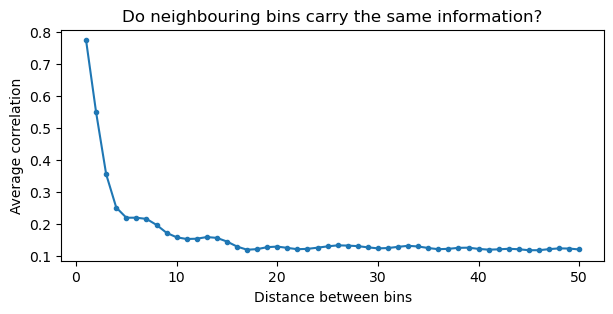

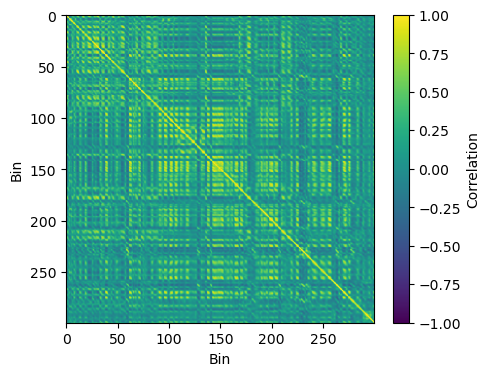

Average correlation with the next bin: 0.775
Bins that are > 0.9 correlated with their next neighbour: 345 of 5999


In [53]:
import matplotlib.pyplot as plt

# Correlation between every pair of bins (6,000 x 6,000 table)
# rowvar=False -> columns (bins) are the variables
with np.errstate(invalid="ignore", divide="ignore"):
    C = np.corrcoef(X.astype("float32"), rowvar=False)
C = np.nan_to_num(C)          # bins that never change give NaN -> set to 0

# 1) Average correlation between bins at distance "lag" (1 = direct neighbour)
lags = range(1, 51)
mean_corr = [C.diagonal(l).mean() for l in lags]   # diagonal(l) = pairs (i, i+l)

plt.figure(figsize=(7, 3))
plt.plot(list(lags), mean_corr, marker="o", markersize=3)
plt.xlabel("Distance between bins")
plt.ylabel("Average correlation")
plt.title("Do neighbouring bins carry the same information?")
plt.show()

# 2) Heatmap of the first 300 bins (bright = strongly correlated)
plt.figure(figsize=(5, 4))
plt.imshow(C[:300, :300], cmap="viridis", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xlabel("Bin"); plt.ylabel("Bin")
plt.show()

# 3) Numbers for the report
print("Average correlation with the next bin:", round(mean_corr[0], 3))
n_high = (C.diagonal(1) > 0.9).sum()
print("Bins that are > 0.9 correlated with their next neighbour:", n_high, "of 5999")

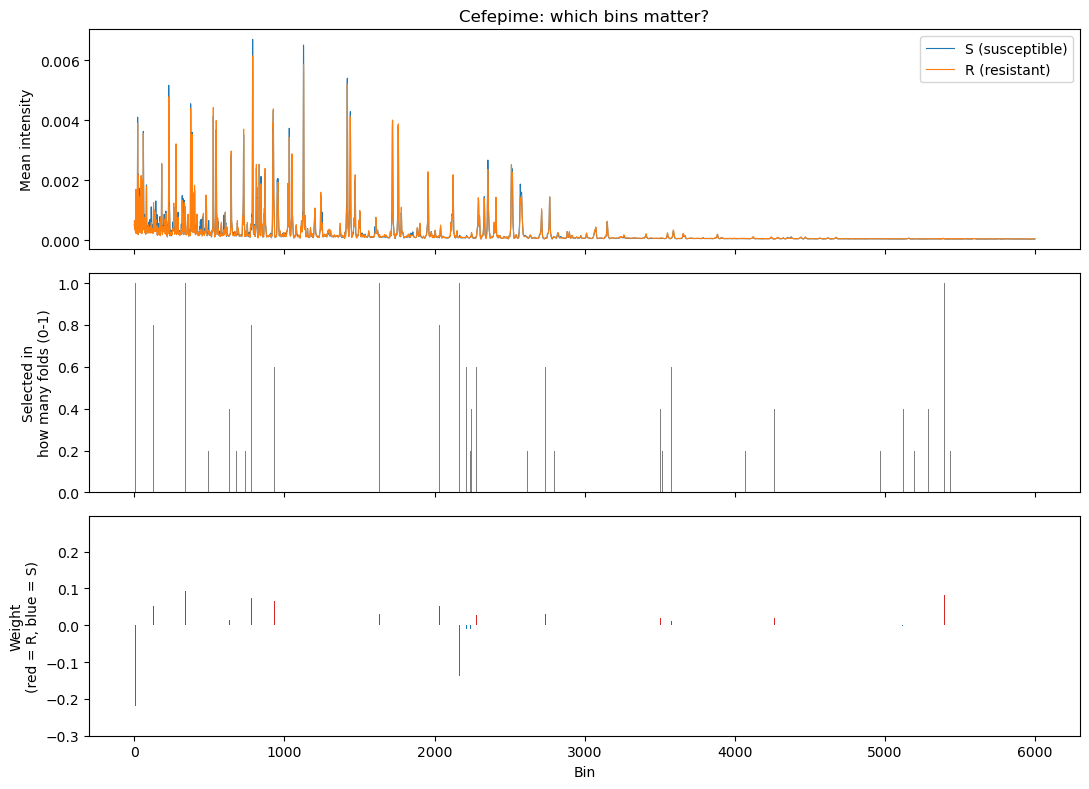

Bins selected in all 5 folds: 31 | in at least 1 fold: 212


,bin,approx_Da,weight,points_to,selected_in_folds
0,86,2258,-0.273,S,1.0
1,2148,8444,0.270,R,1.0
2,1634,6902,0.248,R,1.0
3,8,2024,-0.219,S,1.0
4,278,2834,0.206,R,1.0
5,45,2135,0.187,R,1.0
6,1297,5891,0.164,R,1.0
7,2166,8498,-0.137,S,1.0
8,51,2153,0.131,R,1.0
9,2214,8642,-0.127,S,1.0


In [59]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

abx = "Cefepime"      # change this to look at another antibiotic

# Take the isolates that have an R/S result for this antibiotic
has = lab[abx].notna() & (lab[f"fold_{abx}"] >= 0)
Xa = X[has.values]
ya = lab.loc[has, abx].astype(int).values        # R=1, S=0
fa = lab.loc[has, f"fold_{abx}"].values          # fold numbers 0-4

# Put all bins on the same scale. This cell is only for interpretation, not for scoring.
Xs = StandardScaler().fit_transform(Xa)

# 1) Stability: in how many of the 5 folds was each bin selected? (1.0 = every time)
freq = np.zeros(6000)
for k in range(5):
    sel = LassoSelect(0.03).fit(Xs[fa != k], ya[fa != k])   # fit on 4 folds
    freq += (sel.weights_ > 0)                               # count the selected bins
freq /= 5

# 2) Direction: one fit on all the data, signed weights (+ = more intense in R, - = in S)
m = LogisticRegression(penalty="l1", solver="liblinear", C=0.03, max_iter=1000).fit(Xs, ya)
coef = m.coef_[0]

# 3) Plot: mean spectrum of R and S, selection stability, and weights, along the same bin axis
fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
ax[0].plot(Xa[ya == 0].mean(0), label="S (susceptible)", lw=0.8)
ax[0].plot(Xa[ya == 1].mean(0), label="R (resistant)", lw=0.8)
ax[0].set_ylabel("Mean intensity"); ax[0].legend(); ax[0].set_title(f"{abx}: which bins matter?")
ax[1].bar(range(6000), freq, width=1.0, color="gray")
ax[1].set_ylabel("Selected in\nhow many folds (0-1)")
ax[2].bar(range(6000), coef, width=1.0, color=np.where(coef > 0, "tab:red", "tab:blue"))
ax[2].set_ylabel("Weight\n(red = R, blue = S)"); ax[2].set_xlabel("Bin")
plt.tight_layout(); plt.show()

# 4) Table of the strongest bins
top = np.argsort(-np.abs(coef))[:10]
tbl = pd.DataFrame({"bin": top,
                    "approx_Da": 2000 + 3 * top,    # assumes 3 Da bins starting at 2,000 Da (check the DRIAMS paper)
                    "weight": coef[top].round(3),
                    "points_to": np.where(coef[top] > 0, "R", "S"),
                    "selected_in_folds": freq[top]})
print("Bins selected in all 5 folds:", int((freq == 1).sum()), "| in at least 1 fold:", int((freq > 0).sum()))
display(tbl)

In [60]:
# Share of resistant (R) isolates per year for this antibiotic
chk = lab.loc[has, ["year", abx]].groupby("year")[abx].agg(["count", "mean"])
chk.columns = ["isolates", "R_share"]
display(chk.round(3))

,isolates,R_share
year,,
2015.0,83,0.205
2016.0,1239,0.106
2017.0,1836,0.066
2018.0,1228,0.053


In [61]:
# Year check: tests whether our results depend on the year (R share fell from 20% in 2015 to 5% in 2018):
# (1) how well the year alone predicts resistance, and
# (2) train on 2015-2017, test on 2018, comparing all 6,000 bins vs LASSO.

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

rows = []
for abx in MODEL_ABX:
    h = lab[abx].notna()                           # isolates with an R/S result
    yr = lab.loc[h, "year"].values
    Xa = X[h.values]
    ya = lab.loc[h, abx].astype(int).values        # R=1, S=0
    tr, te = yr <= 2017, yr == 2018                # train: 2015-2017, test: 2018 (later year)

    out = {"antibiotic": abx, "R_share_2018": round(ya[te].mean(), 3)}

    # Check 1: AUC of the year alone (earlier year = more likely R). Near 0.5 = year does not matter
    out["auc_year_only"] = roc_auc_score(ya, -yr)

    # Check 2: same two models as before, but tested on the later year
    for name, red in [("all_bins", None), ("lasso", LassoSelect(0.03))]:
        steps = [StandardScaler()] + ([red] if red is not None else []) + [LogisticRegression(max_iter=1000)]
        p = make_pipeline(*steps).fit(Xa[tr], ya[tr]).predict_proba(Xa[te])[:, 1]
        out[f"auc_{name}"] = roc_auc_score(ya[te], p)
        out[f"prauc_{name}"] = average_precision_score(ya[te], p)
    rows.append(out)

res_year = pd.DataFrame(rows).round(3)
res_year.to_csv("results_train_2015_17_test_2018.csv", index=False)
display(res_year)

,antibiotic,R_share_2018,auc_year_only,auc_all_bins,prauc_all_bins,auc_lasso,prauc_lasso
0,Ampicillin-Amoxicillin,0.598,0.504,0.621,0.707,0.648,0.747
1,Cotrimoxazole,0.310,0.515,0.618,0.431,0.653,0.453
2,Ciprofloxacin,0.262,0.521,0.751,0.574,0.775,0.600
3,Levofloxacin,0.260,0.521,0.750,0.576,0.779,0.603
4,Amoxicillin-Clavulanic acid,0.280,0.487,0.589,0.367,0.597,0.376
5,Ceftriaxone,0.185,0.538,0.846,0.682,0.842,0.687
6,Cefpodoxime,0.431,0.450,0.838,0.830,0.836,0.820
7,Tobramycin,0.115,0.528,0.647,0.193,0.657,0.212
8,Ceftazidime,0.096,0.551,0.785,0.395,0.772,0.355
9,Norfloxacin,0.199,0.539,0.681,0.404,0.694,0.414


In [ ]:
#trying other approches


In [68]:
# cell 1 look at the raw values 

# PURPOSE: look at the raw intensities before changing anything.
# WHY: a transform only helps if the values are skewed (a few huge peaks, most near 0).
# EXPECT: min >= 0 (so sqrt is safe); many tiny values; row-sum std near 0 means the spectra are already normalised.
print("Smallest value:", X.min(), "| largest value:", X.max())
print("Share of values below 1e-4:", round((X < 1e-4).mean(), 3))
rs = X.sum(axis=1)
print("Row sums (mean, std):", round(rs.mean(), 3), round(rs.std(), 3))

Smallest value: 0.0 | largest value: 0.034361534
Share of values below 1e-4: 0.602
Row sums (mean, std): 1.342 0.066


In [69]:
#Cell 2: Define the versions of the data

import warnings
warnings.filterwarnings("ignore", message=".*penalty.*")   # hides repeated scikit-learn messages about "penalty"

# PURPOSE: build the versions of the data we want to compare.
# WHY: sqrt and log shrink the huge peaks so they stop dominating. No labels are used, so there is no leakage.
# EXPECT: scores change a little; we keep a version only if it helps clearly (see Cell 4).
X_raw = X.copy()                                   # keep the original, never overwritten

VARIANTS = {
    "sqrt": np.sqrt(X_raw),                        # square root: mild shrinking of big peaks
    "log":  np.log1p(X_raw / 1e-3),                # log: stronger shrinking (1e-3 = typical intensity size)
}

def run_all_on(X_variant, method_name, reducer):
    """Run one reducer on the 12 antibiotics using X_variant. run_cv itself is NOT changed."""
    global X
    X_backup = X
    X = X_variant                                  # run_cv reads the global X, so we swap it temporarily
    try:
        rows = []
        for abx in MODEL_ABX:
            r = run_cv(reducer, abx)
            r["method"] = method_name
            rows.append(r)
    finally:
        X = X_backup                               # always put the original back
    res = pd.DataFrame(rows)[["antibiotic", "method", "auc", "auc_std", "prauc", "n_features"]]
    res.to_csv(f"results_{method_name}.csv", index=False)
    print(method_name, "mean AUC =", round(res.auc.mean(), 3), "| features =", int(res.n_features.mean()))
    return res

In [70]:
#Cell 3: Run baseline and LASSO on each version

# PURPOSE: run the baseline (all bins) and LASSO on each version, all 12 antibiotics.
# WHY: the baseline shows the effect on the plain data; LASSO shows the effect on a reduction method.
# EXPECT: if a transform helps, BOTH go up. If only one moves, it is probably noise. Takes about 10-15 min.
prep_results = {}
for name, Xv in VARIANTS.items():
    prep_results[f"baseline_{name}"] = run_all_on(Xv, f"baseline_{name}", None)
    prep_results[f"lasso_{name}"]    = run_all_on(Xv, f"lasso_{name}", LassoSelect(0.03))

baseline_sqrt mean AUC = 0.747 | features = 6000
lasso_sqrt mean AUC = 0.758 | features = 243
baseline_log mean AUC = 0.747 | features = 6000
lasso_log mean AUC = 0.76 | features = 243


In [71]:
#Cell 4: Decide whether it helped

# PURPOSE: compare each version with the raw-data results we already have.
# WHY: one antibiotic can move by 0.02 by chance, so we judge by the mean AUC and how many of the 12 improved.
# EXPECT: keep a transform only if mean AUC rises by >= 0.005 AND it wins on >= 8 of 12 antibiotics.
ref = {"baseline": pd.read_csv("results_baseline.csv").set_index("antibiotic")["auc"],
       "lasso":    pd.read_csv("results_lasso.csv").set_index("antibiotic")["auc"]}

rows = []
for key, res in prep_results.items():
    kind, variant = key.split("_")
    new = res.set_index("antibiotic")["auc"]
    diff = (new - ref[kind]).loc[MODEL_ABX]
    rows.append({"method": key, "mean_AUC_raw": round(ref[kind].mean(), 3),
                 "mean_AUC_new": round(new.mean(), 3), "change": round(diff.mean(), 3),
                 "wins_of_12": int((diff > 0).sum()),
                 "keep?": "YES" if diff.mean() >= 0.005 and (diff > 0).sum() >= 8 else "no"})
display(pd.DataFrame(rows))

,method,mean_AUC_raw,mean_AUC_new,change,wins_of_12,keep?
0,baseline_sqrt,0.744,0.747,0.002,8,no
1,lasso_sqrt,0.757,0.758,0.000,7,no
2,baseline_log,0.744,0.747,0.003,8,no
3,lasso_log,0.757,0.760,0.003,9,no


In [74]:
#Cell 3 (optional): Which C each antibiotic chose

# PURPOSE: show which C was chosen for each antibiotic (one fit on all its data).
# WHY: explains why some antibiotics keep many bins and others few; useful for the report.
# EXPECT: weak antibiotics (Ampicillin, Cotrimoxazole) may pick a different C than Cefepime.
from sklearn.preprocessing import StandardScaler
chosen = []
for abx in MODEL_ABX:
    has = lab[abx].notna() & (lab[f"fold_{abx}"] >= 0)
    Xs = StandardScaler().fit_transform(X[has.values])
    sel = LassoAutoC().fit(Xs, lab.loc[has, abx].astype(int).values)
    chosen.append({"antibiotic": abx, "chosen_C": sel.C_, "bins_kept": int(sel.mask_.sum())})
display(pd.DataFrame(chosen))

,antibiotic,chosen_C,bins_kept
0,Ampicillin-Amoxicillin,0.02,310
1,Cotrimoxazole,0.01,50
2,Ciprofloxacin,0.02,201
3,Levofloxacin,0.02,197
4,Amoxicillin-Clavulanic acid,0.02,223
5,Ceftriaxone,0.03,356
6,Cefpodoxime,0.03,174
7,Tobramycin,0.03,266
8,Ceftazidime,0.03,184
9,Norfloxacin,0.05,238


In [77]:
#Cell 3: Stability, the real test
# PURPOSE: measure STABILITY: how much do the chosen bins change between the 5 training folds?
# WHY: this is the real reason to try Elastic Net. Stable bins = regions we can trust and explain.
# EXPECT: Elastic Net has a higher "jaccard" (overlap between folds, 1 = identical) and more bins chosen in all 5 folds.
from sklearn.preprocessing import StandardScaler

def selection_stability(make_selector, abx):
    has = lab[abx].notna() & (lab[f"fold_{abx}"] >= 0)
    Xa = X[has.values]; ya = lab.loc[has, abx].astype(int).values; fa = lab.loc[has, f"fold_{abx}"].values
    masks = []
    for k in range(5):
        tr = fa != k                                         # training part of fold k
        Z = StandardScaler().fit_transform(Xa[tr])
        masks.append(make_selector().fit(Z, ya[tr]).mask_)   # which bins were chosen in this fold
    M = np.array(masks)
    jac = np.mean([(M[i] & M[j]).sum() / (M[i] | M[j]).sum()
                   for i in range(5) for j in range(i + 1, 5)])   # overlap between each pair of folds
    return {"bins_per_fold": int(M.sum(1).mean()), "chosen_in_all_5": int(M.all(0).sum()),
            "chosen_in_any": int(M.any(0).sum()), "jaccard": round(jac, 2)}

rows = []
for abx in ["Levofloxacin", "Cefepime", "Ampicillin-Amoxicillin"]:
    for name, maker in [("lasso_C0.03", lambda: LassoSelect(0.03)),
                        (f"elasticnet_C{EN_C}", lambda: ElasticNetSelect(EN_C))]:
        rows.append({"antibiotic": abx, "method": name, **selection_stability(maker, abx)})
display(pd.DataFrame(rows))

/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max

,antibiotic,method,bins_per_fold,chosen_in_all_5,chosen_in_any,jaccard
0,Levofloxacin,lasso_C0.03,319,71,787,0.31
1,Levofloxacin,elasticnet_C0.015,399,119,900,0.36
2,Cefepime,lasso_C0.03,96,28,206,0.40
3,Cefepime,elasticnet_C0.015,149,56,308,0.43
4,Ampicillin-Amoxicillin,lasso_C0.03,470,101,1166,0.31
5,Ampicillin-Amoxicillin,elasticnet_C0.015,534,131,1274,0.33


## Results: reducing the 6,000 bins (E. coli, Hospital A, 12 antibiotics)

**Question:** can we predict resistance with far fewer than 6,000 bins?
**Fair test:** the same Logistic Regression, the same 5 folds, and the reduction fitted on the training folds only (no leakage). Score = AUC (0.5 = random guess, 1.0 = perfect).

### The methods
| Method | How it works | Where it comes from |
|---|---|---|
| **Baseline** | Uses all 6,000 bins. The reference. | None (no reduction) |
| **MI top 100** (Mutual Information) | Scores each bin on its own by how much it tells us about R vs S, keeps the best 100. A *filter*. | Standard feature-selection method, scikit-learn `mutual_info_classif` |
| **LASSO** | Logistic Regression with an L1 penalty that sets the weight of useless bins to exactly 0. The model chooses the bins. An *embedded* method. | Tibshirani (1996), scikit-learn `LogisticRegression(penalty="l1")` |
| **LASSO auto C** | Same, but the penalty strength C is chosen separately for each antibiotic inside the training folds. | Standard cross-validation, our own small wrapper |
| **Elastic Net** | LASSO plus a small ridge (L2) penalty, to keep groups of similar bins together. | Zou & Hastie (2005), scikit-learn `penalty="elasticnet"` |

All methods are established; we did not invent them. They were implemented with scikit-learn, plugged into our common test (`run_cv`), and the code was written with AI assistance (Claude) and run and checked by me.

### Results (mean AUC over 12 antibiotics)
| Method | AUC | Bins used |
|---|---|---|
| Baseline | 0.744 | 6,000 |
| MI top 100 | 0.739 | 100 |
| LASSO (fixed C) | 0.757 | about 240 |
| LASSO (auto C) | 0.755 | about 224 |
| Elastic Net | 0.756 | about 300 |

### What it means
- About 200 bins give the same score as all 6,000, so most of the spectrum is redundant (neighbouring bins correlate at 0.78).
- LASSO is the best method that keeps real, explainable bins; MI is slightly weaker and fails with few resistant samples.
- Elastic Net gives the same accuracy as LASSO (slightly more stable bins, no gain in AUC).
- Square-root and log transforms changed the AUC by at most 0.003, so the raw spectra are used.
- Testing on a later year (train 2015-2017, test 2018) costs about 0.03 AUC, so the signal is real.

### Limits
- Selected bins change between folds (overlap about 0.3-0.4), so they are hypotheses, not proven biology.
- Antibiotics with few resistant samples (Pip-Tazo, Tobramycin, Norfloxacin) are unreliable.
- One hospital; 12 of 15 antibiotics.

# Machine learning

Same data, same folds, same reductions as before. Only the classifier changes (Logistic Regression was the reference).

**How `run_cv_ml` works:** for each fold it scales and reduces the training data once, then trains every model on it. This saves time, because the slow reductions (LASSO auto C) are not repeated for each model. All results go into one file, `results_ml_1.csv`.

## My models

| Model | How it works (very short) |
|---|---|
| Gradient boosting | Builds many small decision trees one after another. Each new tree fixes the mistakes of the previous ones. |
| SVM (Support Vector Machine) | Finds the boundary that separates R from S with the widest margin. The RBF kernel lets the boundary curve. |
| MLP (Multi-Layer Perceptron) | A small neural network: layers of simple units that learn a combination of the inputs. |

Settings are default or simple for now. We tune them later, inside the training folds only.

In [83]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

def get_scores(model, X):
    """Score for 'resistant'. AUC and PR-AUC only need the ranking, so any score works."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)          # SVM gives a distance instead of a probability

def run_cv_ml(reducer, models, antibiotic):
    """Same folds as run_cv. Scaler + reducer are fitted ONCE per fold, then every model reuses them."""
    has_label = (lab[antibiotic].notna()) & (lab[f"fold_{antibiotic}"] >= 0)
    Xa = X[has_label.values]
    ya = lab.loc[has_label, antibiotic].astype(int).values
    fa = lab.loc[has_label, f"fold_{antibiotic}"].values

    scores = {name: {"auc": [], "prauc": []} for name in models}
    n_feats = []
    for k in range(5):
        tr, te = fa != k, fa == k
        steps = [StandardScaler()]
        if reducer is not None:
            steps.append(clone(reducer))
        prep = make_pipeline(*steps).fit(Xa[tr], ya[tr])        # fitted on the training folds only
        Ztr, Zte = prep.transform(Xa[tr]), prep.transform(Xa[te])
        n_feats.append(Ztr.shape[1])
        for name, model in models.items():
            m = clone(model).fit(Ztr, ya[tr])                   # fresh copy of the classifier
            p = get_scores(m, Zte)
            scores[name]["auc"].append(roc_auc_score(ya[te], p))
            scores[name]["prauc"].append(average_precision_score(ya[te], p))

    return [{"antibiotic": antibiotic, "model": name,
             "auc": np.mean(s["auc"]), "auc_std": np.std(s["auc"]),
             "prauc": np.mean(s["prauc"]), "n_features": int(np.mean(n_feats))}
            for name, s in scores.items()]

def run_all_ml(input_name, reducer, models, antibiotics=None):
    """Run the models on the 12 antibiotics and save results_<input>_<model>.csv for each model."""
    rows = []
    for abx in (antibiotics or MODEL_ABX):
        for r in run_cv_ml(reducer, models, abx):
            r["method"] = input_name
            rows.append(r)
            print(input_name, "|", r["model"], "|", abx, "| AUC =", round(r["auc"], 3),
                  "| PR-AUC =", round(r["prauc"], 3))
    res = pd.DataFrame(rows)
    for name in models:
        out = res[res.model == name][["antibiotic", "method", "auc", "auc_std", "prauc", "n_features"]]
        out.to_csv(f"results_{input_name}_{name}.csv", index=False)
        print(input_name, name, "mean AUC =", round(out.auc.mean(), 3))
    return res

MY_MODELS = {
    "gboost": HistGradientBoostingClassifier(random_state=0),   # gradient boosting
    "svm":    SVC(kernel="rbf", C=1.0, gamma="scale"),
    "mlp":    MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-2, early_stopping=True,
                            max_iter=200, random_state=0),
}

# Quick test: Kernel PCA input, Cefepime only
test = run_cv_ml(KernelPCAScaled(n_components=200, kernel="rbf"), MY_MODELS, "Cefepime")
display(pd.DataFrame(test).round(3))
# Reference: Logistic Regression gave Cefepime AUC 0.856 on this input

,antibiotic,model,auc,auc_std,prauc,n_features
0,Cefepime,gboost,0.851,0.024,0.453,200
1,Cefepime,svm,0.877,0.020,0.519,200
2,Cefepime,mlp,0.855,0.018,0.472,200


In [84]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

def get_scores(model, X):
    """Score for 'resistant'. AUC and PR-AUC only need the ranking, so any score works."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)          # SVM gives a distance instead of a probability

def run_cv_ml(reducer, models, antibiotic):
    """Same folds as run_cv. Scaler + reducer are fitted ONCE per fold, then every model reuses them."""
    has_label = (lab[antibiotic].notna()) & (lab[f"fold_{antibiotic}"] >= 0)
    Xa = X[has_label.values]
    ya = lab.loc[has_label, antibiotic].astype(int).values
    fa = lab.loc[has_label, f"fold_{antibiotic}"].values

    scores = {name: {"auc": [], "prauc": []} for name in models}
    n_feats = []
    for k in range(5):
        tr, te = fa != k, fa == k
        steps = [StandardScaler()]
        if reducer is not None:
            steps.append(clone(reducer))
        prep = make_pipeline(*steps).fit(Xa[tr], ya[tr])        # fitted on the training folds only
        Ztr, Zte = prep.transform(Xa[tr]), prep.transform(Xa[te])
        n_feats.append(Ztr.shape[1])
        for name, model in models.items():
            m = clone(model).fit(Ztr, ya[tr])                   # fresh copy of the classifier
            p = get_scores(m, Zte)
            scores[name]["auc"].append(roc_auc_score(ya[te], p))
            scores[name]["prauc"].append(average_precision_score(ya[te], p))

    return [{"antibiotic": antibiotic, "model": name,
             "auc": np.mean(s["auc"]), "auc_std": np.std(s["auc"]),
             "prauc": np.mean(s["prauc"]), "n_features": int(np.mean(n_feats))}
            for name, s in scores.items()]

def run_all_ml(input_name, reducer, models, antibiotics=None):
    """Run the models on the 12 antibiotics. Returns one table; nothing is saved here."""
    rows = []
    for abx in (antibiotics or MODEL_ABX):
        for r in run_cv_ml(reducer, models, abx):
            r["input"] = input_name
            rows.append(r)
            print(input_name, "|", r["model"], "|", abx, "| AUC =", round(r["auc"], 3),
                  "| PR-AUC =", round(r["prauc"], 3))
    return pd.DataFrame(rows)[["antibiotic", "input", "model", "auc", "auc_std", "prauc", "n_features"]]

MY_MODELS = {
    "gboost": HistGradientBoostingClassifier(random_state=0),   # gradient boosting
    "svm":    SVC(kernel="rbf", C=1.0, gamma="scale"),
    "mlp":    MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-2, early_stopping=True,
                            max_iter=200, random_state=0),
}

In [85]:
# Run my 3 models on all 12 antibiotics for each of the 4 inputs.
# Everything goes into ONE file: results_ml_1.csv (updated after each input).
# If you stop and restart, inputs already in the file are skipped.
import os

INPUTS = {
    "kpca_rbf":      KernelPCAScaled(n_components=200, kernel="rbf"),
    "grouped_anova": GroupedANOVASelector(group_size=10, n_groups=30, top_bins_per_group=3),
    "lasso_autoC":   LassoAutoC(),
    "all_bins":      None,                    # None = no reduction, all 6,000 bins
}

OUT = "results_ml_1.csv"
all_ml = pd.read_csv(OUT) if os.path.exists(OUT) else pd.DataFrame()

for input_name, reducer in INPUTS.items():
    if len(all_ml) and input_name in set(all_ml["input"]):
        print(input_name, "already done, skipped")
        continue
    t = time.time()
    res = run_all_ml(input_name, reducer, MY_MODELS)
    all_ml = pd.concat([all_ml, res], ignore_index=True)
    all_ml.to_csv(OUT, index=False)          # saved after each input
    print(input_name, "finished in", round((time.time() - t) / 60, 1), "min\n")

# Summary: mean AUC over the 12 antibiotics, rows = input, columns = model
display(all_ml.groupby(["input", "model"]).auc.mean().unstack().round(3))

kpca_rbf | gboost | Ampicillin-Amoxicillin | AUC = 0.69 | PR-AUC = 0.78
kpca_rbf | svm | Ampicillin-Amoxicillin | AUC = 0.717 | PR-AUC = 0.802
kpca_rbf | mlp | Ampicillin-Amoxicillin | AUC = 0.715 | PR-AUC = 0.8
kpca_rbf | gboost | Cotrimoxazole | AUC = 0.692 | PR-AUC = 0.511
kpca_rbf | svm | Cotrimoxazole | AUC = 0.719 | PR-AUC = 0.548
kpca_rbf | mlp | Cotrimoxazole | AUC = 0.702 | PR-AUC = 0.523
kpca_rbf | gboost | Ciprofloxacin | AUC = 0.805 | PR-AUC = 0.691
kpca_rbf | svm | Ciprofloxacin | AUC = 0.824 | PR-AUC = 0.741
kpca_rbf | mlp | Ciprofloxacin | AUC = 0.822 | PR-AUC = 0.722
kpca_rbf | gboost | Levofloxacin | AUC = 0.814 | PR-AUC = 0.703
kpca_rbf | svm | Levofloxacin | AUC = 0.821 | PR-AUC = 0.734
kpca_rbf | mlp | Levofloxacin | AUC = 0.825 | PR-AUC = 0.726
kpca_rbf | gboost | Amoxicillin-Clavulanic acid | AUC = 0.674 | PR-AUC = 0.426
kpca_rbf | svm | Amoxicillin-Clavulanic acid | AUC = 0.697 | PR-AUC = 0.476
kpca_rbf | mlp | Amoxicillin-Clavulanic acid | AUC = 0.66 | PR-AUC = 

model,gboost,mlp,svm
input,,,
all_bins,0.793,0.768,0.796
grouped_anova,0.783,0.768,0.792
kpca_rbf,0.771,0.768,0.791
lasso_autoC,0.784,0.761,0.783


## ML results: what we observed

Mean AUC over the 12 antibiotics (higher is better; Logistic Regression was the reference).

| Input | Logistic Regression | Gradient boosting | SVM | MLP |
|---|---|---|---|---|
| All 6,000 bins | 0.744 | 0.793 | **0.796** | 0.768 |
| Grouped ANOVA 300 | 0.755 | 0.783 | 0.792 | 0.768 |
| Kernel PCA RBF-200 | 0.772 | 0.771 | 0.791 | 0.768 |
| LASSO auto C | 0.756 | 0.784 | 0.783 | 0.761 |

**What we observed**
- **ML models beat Logistic Regression.** The best result is SVM on all 6,000 bins (0.796), +0.05 over the baseline.
- **SVM is the best model overall,** then gradient boosting, then the MLP (the MLP is untuned).
- **Reduction does not improve accuracy for these models.** All 6,000 bins does as well as the reduced inputs; the differences between inputs (about 0.01) are within the noise. Reduction mainly gives speed and a smaller feature set.
- **Kernel PCA was best only for Logistic Regression.** The advantage does not carry over to the other models.
- **Hard antibiotics stay hard** (Piperacillin-Tazobactam, Amoxicillin-Clavulanic acid, Cotrimoxazole: best AUC 0.70–0.74).

**Limits:** settings are default and untuned; one antibiotic varies by about 0.02 between folds, so small gaps are not real differences.

## Tuning

Same models, but now each one picks its own settings. Inside each training fold, a 3-fold validation tries a small grid of settings and keeps the best by AUC. The test fold is never used for tuning, so there is no leakage.

| Model | Settings tried |
|---|---|
| Gradient boosting | learning rate (0.05, 0.1), tree size (8 or 31 leaves) |
| SVM | C: how strict the boundary is (0.3, 1, 3, 10) |
| MLP | layer size (64 or 128 units), regularisation alpha (0.001, 0.01, 0.1) |

Run on all 4 inputs (Kernel PCA RBF-200, Grouped ANOVA 300, LASSO auto C, all 6,000 bins), so we can compare **before and after tuning** for each model and input. Tuned results are stored in the same file with names ending in `_tuned`.

In [86]:
from sklearn.model_selection import GridSearchCV

def tuned(model, grid):
    """Wrap a model so it picks its settings with 3-fold validation. run_cv_ml fits it on the
    TRAINING folds only, so the test fold is never used for tuning."""
    return GridSearchCV(model, grid, cv=3, scoring="roc_auc", n_jobs=-1)

TUNED_MODELS = {
    "gboost_tuned": tuned(HistGradientBoostingClassifier(random_state=0),
                          {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [8, 31]}),
    "svm_tuned":    tuned(SVC(kernel="rbf", gamma="scale"),
                          {"C": [0.3, 1, 3, 10]}),
    "mlp_tuned":    tuned(MLPClassifier(early_stopping=True, max_iter=200, random_state=0),
                          {"hidden_layer_sizes": [(64,), (128,)], "alpha": [1e-3, 1e-2, 1e-1]}),
}

# Quick test: Grouped ANOVA input, Cefepime only
t = time.time()
test = run_cv_ml(GroupedANOVASelector(group_size=10, n_groups=30, top_bins_per_group=3),
                 TUNED_MODELS, "Cefepime")
print("Time:", round(time.time() - t), "seconds for one antibiotic")
display(pd.DataFrame(test)[["antibiotic", "model", "auc", "auc_std", "prauc"]].round(3))
# Untuned, same input and antibiotic: gradient boosting 0.883 | SVM 0.882 | MLP 0.851

Time: 62 seconds for one antibiotic


,antibiotic,model,auc,auc_std,prauc
0,Cefepime,gboost_tuned,0.876,0.021,0.509
1,Cefepime,svm_tuned,0.888,0.021,0.563
2,Cefepime,mlp_tuned,0.861,0.026,0.476


In [87]:
# Tuned models on all 12 antibiotics for all 4 inputs.
# Results are ADDED to the same file (results_ml_1.csv) with model names ending in _tuned.
# If you stop and restart, finished inputs are skipped.
TUNE_INPUTS = {
    "kpca_rbf":      KernelPCAScaled(n_components=200, kernel="rbf"),
    "grouped_anova": GroupedANOVASelector(group_size=10, n_groups=30, top_bins_per_group=3),
    "lasso_autoC":   LassoAutoC(),
    "all_bins":      None,
}

all_ml = pd.read_csv("results_ml_1.csv")
for input_name, reducer in TUNE_INPUTS.items():
    if ((all_ml["input"] == input_name) & (all_ml["model"] == "svm_tuned")).any():
        print(input_name, "already done, skipped")
        continue
    t = time.time()
    res = run_all_ml(input_name, reducer, TUNED_MODELS)
    all_ml = pd.concat([all_ml, res], ignore_index=True)
    all_ml.to_csv("results_ml_1.csv", index=False)          # saved after each input
    print(input_name, "finished in", round((time.time() - t) / 60, 1), "min\n")

# Before vs after tuning: mean AUC over the 12 antibiotics
m = all_ml.groupby(["input", "model"]).auc.mean().unstack()
cmp = pd.DataFrame(index=m.index)
for b in ["gboost", "svm", "mlp"]:
    cmp[f"{b}_before"] = m[b]
    cmp[f"{b}_after"] = m[f"{b}_tuned"]
    cmp[f"{b}_change"] = m[f"{b}_tuned"] - m[b]
display(cmp.round(3))

kpca_rbf | gboost_tuned | Ampicillin-Amoxicillin | AUC = 0.689 | PR-AUC = 0.778
kpca_rbf | svm_tuned | Ampicillin-Amoxicillin | AUC = 0.749 | PR-AUC = 0.827
kpca_rbf | mlp_tuned | Ampicillin-Amoxicillin | AUC = 0.728 | PR-AUC = 0.812
kpca_rbf | gboost_tuned | Cotrimoxazole | AUC = 0.689 | PR-AUC = 0.507
kpca_rbf | svm_tuned | Cotrimoxazole | AUC = 0.724 | PR-AUC = 0.551
kpca_rbf | mlp_tuned | Cotrimoxazole | AUC = 0.715 | PR-AUC = 0.533
kpca_rbf | gboost_tuned | Ciprofloxacin | AUC = 0.804 | PR-AUC = 0.687
kpca_rbf | svm_tuned | Ciprofloxacin | AUC = 0.839 | PR-AUC = 0.756
kpca_rbf | mlp_tuned | Ciprofloxacin | AUC = 0.831 | PR-AUC = 0.732
kpca_rbf | gboost_tuned | Levofloxacin | AUC = 0.81 | PR-AUC = 0.694
kpca_rbf | svm_tuned | Levofloxacin | AUC = 0.838 | PR-AUC = 0.749
kpca_rbf | mlp_tuned | Levofloxacin | AUC = 0.821 | PR-AUC = 0.72
kpca_rbf | gboost_tuned | Amoxicillin-Clavulanic acid | AUC = 0.675 | PR-AUC = 0.434
kpca_rbf | svm_tuned | Amoxicillin-Clavulanic acid | AUC = 0.698 

,gboost_before,gboost_after,gboost_change,svm_before,svm_after,svm_change,mlp_before,mlp_after,mlp_change
input,,,,,,,,,
all_bins,0.793,0.789,-0.005,0.796,0.807,0.011,0.768,0.765,-0.003
grouped_anova,0.783,0.781,-0.002,0.792,0.795,0.003,0.768,0.769,0.001
kpca_rbf,0.771,0.767,-0.004,0.791,0.805,0.014,0.768,0.772,0.004
lasso_autoC,0.784,0.784,0.000,0.783,0.783,0.000,0.761,0.763,0.002


## Tuning results: what we observed

Mean AUC over the 12 antibiotics, before and after tuning (each model chose its settings inside the training folds only).

| Input | Gradient boosting | | SVM | | MLP | |
|---|---|---|---|---|---|---|
| | before → after | change | before → after | change | before → after | change |
| All 6,000 bins | 0.793 → 0.789 | −0.005 | 0.796 → **0.807** | +0.011 | 0.768 → 0.765 | −0.003 |
| Kernel PCA RBF-200 | 0.771 → 0.767 | −0.004 | 0.791 → **0.805** | +0.014 | 0.768 → 0.772 | +0.004 |
| Grouped ANOVA 300 | 0.783 → 0.781 | −0.002 | 0.792 → 0.795 | +0.003 | 0.768 → 0.769 | +0.001 |
| LASSO auto C | 0.784 → 0.784 | 0.000 | 0.783 → 0.783 | 0.000 | 0.761 → 0.763 | +0.002 |

**What we observed**
- **Tuning helped the SVM a little.** It gained +0.011 to +0.014 on the 6,000 bins and on Kernel PCA, and the gain is small but consistent across antibiotics.
- **Gradient boosting and the MLP did not improve.** Their changes (within ±0.005) are below the noise, so the default settings were already close to the best the small grid could find.
- **The ranking did not change:** SVM > gradient boosting > MLP.
- **Reduction still gives no accuracy advantage.** Kernel PCA (200 features) is within 0.002 of all 6,000 bins for the tuned SVM, and tuning it took 27 min against about 7 hours for the 6,000 bins.
- **Best result so far:** tuned SVM, 0.807 (6,000 bins) and 0.805 (Kernel PCA RBF-200).

**Limits:** small tuning grids; one antibiotic varies by about 0.02 between folds, so gaps below about 0.01 are not real differences.